In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!nvidia-smi

Mounted at /content/drive
Fri Oct 30 17:59:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

Extracting ZIP

In [ ]:
import os, glob, zipfile

DRIVE_DIR   = '/content/drive/MyDrive/AMD_Project_Final'
EXTRACT_DIR = '/content/data'

os.makedirs(EXTRACT_DIR, exist_ok=True)

zips = sorted(glob.glob(os.path.join(DRIVE_DIR, '*.zip')))
print("Drive folder:", DRIVE_DIR)
print("ZIP:", zips)

if len(zips) == 0:
    raise SystemExit("❌ AMDNet23 ZIP not found. Upload on drive- AMD_Project_Final ")

for z in zips:
    name = os.path.basename(z).replace('.zip','')
    out  = os.path.join(EXTRACT_DIR, name)
    os.makedirs(out, exist_ok=True)
    print(f"\n⏳ Extracted: {z}  →  {out}")
    try:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(out)
        print("✅ Extract done")
    except zipfile.BadZipFile:
        raise SystemExit(f"❌ BadZipFile: {z} — not completed")

print("\n📂 Extract level:")
for d in os.listdir(EXTRACT_DIR):
    print("  -", d)

Drive folder: /content/drive/MyDrive/AMD_Project_Final
ZIP: ['/content/drive/MyDrive/AMD_Project_Final/A Multi-Class Retinal Fundus Image Dataset for Dee.zip', '/content/drive/MyDrive/AMD_Project_Final/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip', '/content/drive/MyDrive/AMD_Project_Final/Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip']

⏳ Extracted: /content/drive/MyDrive/AMD_Project_Final/A Multi-Class Retinal Fundus Image Dataset for Dee.zip  →  /content/data/A Multi-Class Retinal Fundus Image Dataset for Dee
✅ Extract done

⏳ Extracted: /content/drive/MyDrive/AMD_Project_Final/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip  →  /content/data/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)
✅ Extract done

⏳ Extracted: /content/drive/MyDrive/AMD_Project_Final/Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip  →  /content/data/Banglad

Dataset Structure

In [ ]:
import os

for root in os.listdir(EXTRACT_DIR):
    base = os.path.join(EXTRACT_DIR, root)
    if not os.path.isdir(base): continue
    print("\n====", root, "====")
    for dirpath, dirnames, filenames in os.walk(base):
        level = dirpath.replace(base, '').count(os.sep)
        if level > 2:
            dirnames[:] = []
            continue
        indent = '  ' * level
        print(f"{indent}{os.path.basename(dirpath)}/  ({len(filenames)} files)")
        if level >= 2: dirnames[:] = []


==== AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1) ====
AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/  (0 files)
  AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/  (0 files)
    AMDNet23 Dataset/  (0 files)


In [ ]:
import os

base = '/content/data'
for root in os.listdir(base):
    p = os.path.join(base, root)
    if not os.path.isdir(p): continue

    for dirpath, dirnames, filenames in os.walk(p):
        if len(filenames) > 0:
            rel = os.path.relpath(dirpath, base)
            print(f"{rel}/  →  {len(filenames)} files")

AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/cataract/  →  400 files
AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/amd/  →  394 files
AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/normal/  →  400 files
AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset/train/diabetes/  →  400 files
AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dat

train/valid

In [ ]:
import os, glob
import pandas as pd

SEED = 42
IMG_EXT = ('.jpg','.jpeg','.png','.bmp','.tif','.tiff')

def list_images(folder):
    return [p for p in glob.glob(os.path.join(folder,'**','*'), recursive=True)
            if p.lower().endswith(IMG_EXT)]

#Find the main dataset where train/valod exists
base = '/content/data'
data_root = None
for root in os.listdir(base):
    p = os.path.join(base, root)
    if not os.path.isdir(p): continue
    for dirpath, dirnames, filenames in os.walk(p):
        if 'train' in dirnames and ('valid' in dirnames or 'test' in dirnames):
            data_root = dirpath
            break
    if data_root: break

if data_root is None:
    raise SystemExit("❌ train/valid Folder not found")

print("✅ data_root:", data_root)
print("Inside:", sorted(os.listdir(data_root)))

train_dir = os.path.join(data_root, 'train')
val_dir   = os.path.join(data_root, 'valid') if os.path.isdir(os.path.join(data_root,'valid')) \
            else os.path.join(data_root, 'test')

def build_records(folder):
    recs = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir): continue
        imgs = list_images(cdir)
        for p in imgs:
            recs.append({'path': p, 'label': cls.lower()})
        print(f"  {cls}: {len(imgs)}")
    return pd.DataFrame(recs)

print("\n📂 Train:")
train_df = build_records(train_dir)
print("\n📂 Valid:")
val_df = build_records(val_dir)

print(f"\n📊 Train: {len(train_df)} | Val: {len(val_df)}")
print("\nTrain :")
print(train_df['label'].value_counts())
print("\nVal :")
print(val_df['label'].value_counts())

#Confirmation of train and valid
assert set(train_df['label'].unique()) == set(val_df['label'].unique()), \
    "Train ও Val not in same level"
print("\n✅ Train/Val level matched")

✅ data_root: /content/data/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1)/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection/AMDNet23 Dataset
Inside: ['train', 'valid']

📂 Train:
  amd: 394
  cataract: 400
  diabetes: 400
  normal: 400

📂 Valid:
  amd: 100
  cataract: 100
  diabetes: 100
  normal: 100

📊 Train: 1594 | Val: 400

Train :
label
cataract    400
diabetes    400
normal      400
amd         394
Name: count, dtype: int64

Val :
label
amd         100
cataract    100
diabetes    100
normal      100
Name: count, dtype: int64

✅ Train/Val level matched


Dataset and Data load

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class EyeDataset(Dataset):
    def __init__(self, df, label_to_idx, transform=None):
        self.df = df.reset_index(drop=True)
        self.l2i = label_to_idx
        self.tf = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row['path']).convert('RGB')
        if self.tf: img = self.tf(img)
        return img, self.l2i[row['label']]

label_to_idx = {l:i for i,l in enumerate(sorted(train_df['label'].unique()))}
idx_to_label = {v:k for k,v in label_to_idx.items()}
NUM_CLASSES = len(label_to_idx)
print("Level mapping:", label_to_idx)

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
val_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

BATCH = 16

train_ds = EyeDataset(train_df, label_to_idx, train_tf)
val_ds   = EyeDataset(val_df,   label_to_idx, val_tf)
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
print("Batches → train:", len(train_dl), "| val:", len(val_dl))

Level mapping: {'amd': 0, 'cataract': 1, 'diabetes': 2, 'normal': 3}
Batches → train: 100 | val: 25


model training

In [ ]:
import torch.nn as nn, time
from torchvision import models

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

def build_model(num_classes):
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(DEVICE)

model = build_model(NUM_CLASSES)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train_epoch(dl):
    model.train(); tot=0; corr=0; loss_sum=0
    for x,y in dl:
        x,y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x); loss = criterion(out,y)
        loss.backward(); optimizer.step()
        loss_sum += loss.item()*x.size(0)
        corr += (out.argmax(1)==y).sum().item()
        tot += x.size(0)
    return loss_sum/tot, corr/tot

@torch.no_grad()
def eval_epoch(dl):
    model.eval(); tot=0; corr=0; loss_sum=0
    for x,y in dl:
        x,y = x.to(DEVICE), y.to(DEVICE)
        out = model(x); loss = criterion(out,y)
        loss_sum += loss.item()*x.size(0)
        corr += (out.argmax(1)==y).sum().item()
        tot += x.size(0)
    return loss_sum/tot, corr/tot

# ========== SWITCH ==========
QUICK = True
# ============================

EPOCHS = 2 if QUICK else 30

# QUICK mode DataLoader (Main train_dl/val_dl theke jabe)
if QUICK:
    from torch.utils.data import Subset
    n_tr = min(600, len(train_ds)); n_va = min(200, len(val_ds))
    quick_train_dl = DataLoader(Subset(train_ds, range(n_tr)), batch_size=BATCH, shuffle=True,  num_workers=2)
    quick_val_dl   = DataLoader(Subset(val_ds,   range(n_va)), batch_size=BATCH, shuffle=False, num_workers=2)
    print(f"QUICK Mode: {n_tr} train / {n_va} val")
    cur_train_dl, cur_val_dl = quick_train_dl, quick_val_dl
else:
    cur_train_dl, cur_val_dl = train_dl, val_dl
    print(f"FULL Mode: {len(train_ds)} train / {len(val_ds)} val, {EPOCHS} epochs")

CKPT = '/content/drive/MyDrive/AMD_Project_Final/best_model.pt'
best_val = 0.0

for ep in range(1, EPOCHS+1):
    t0=time.time()
    tl,ta = train_epoch(cur_train_dl)
    vl,va = eval_epoch(cur_val_dl)
    print(f"Epoch {ep}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.1f}s")
    if va > best_val:
        best_val = va
        torch.save({'model':model.state_dict(), 'label_to_idx':label_to_idx}, CKPT)
        print(f"  💾 best (acc={va:.4f}) → {CKPT}")

print(f"\n✅ done. Best val acc = {best_val:.4f}")

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


QUICK Mode: 600 train / 200 val
Epoch 1/2 | train loss 0.3068 acc 0.9050 | val loss 0.0428 acc 0.9900 | 19.1s
  💾 best (acc=0.9900) → /content/drive/MyDrive/AMD_Project_Final/best_model.pt
Epoch 2/2 | train loss 0.0439 acc 0.9867 | val loss 0.0228 acc 0.9950 | 37.0s
  💾 best (acc=0.9950) → /content/drive/MyDrive/AMD_Project_Final/best_model.pt

✅ done. Best val acc = 0.9950


In [ ]:
import torch.nn as nn, time
from torchvision import models
from torch.utils.data import Subset, DataLoader as _DL

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

def build_model(num_classes):
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m.to(DEVICE)

# Building new model
model = build_model(NUM_CLASSES)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def train_epoch(dl):
    model.train(); tot=0; corr=0; loss_sum=0
    for x,y in dl:
        x,y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x); loss = criterion(out,y)
        loss.backward(); optimizer.step()
        loss_sum += loss.item()*x.size(0)
        corr += (out.argmax(1)==y).sum().item()
        tot += x.size(0)
    return loss_sum/tot, corr/tot

@torch.no_grad()
def eval_epoch(dl):
    model.eval(); tot=0; corr=0; loss_sum=0
    for x,y in dl:
        x,y = x.to(DEVICE), y.to(DEVICE)
        out = model(x); loss = criterion(out,y)
        loss_sum += loss.item()*x.size(0)
        corr += (out.argmax(1)==y).sum().item()
        tot += x.size(0)
    return loss_sum/tot, corr/tot

# ========== SWITCH ==========
QUICK = False   # Full training
# ============================

EPOCHS = 2 if QUICK else 30

if QUICK:
    n_tr = min(600, len(train_ds)); n_va = min(200, len(val_ds))
    cur_train_dl = _DL(Subset(train_ds, range(n_tr)), batch_size=BATCH, shuffle=True,  num_workers=2)
    cur_val_dl   = _DL(Subset(val_ds,   range(n_va)), batch_size=BATCH, shuffle=False, num_workers=2)
    print(f"QUICK Mode: {n_tr} train / {n_va} val")
else:
    cur_train_dl, cur_val_dl = train_dl, val_dl
    print(f"FULL Mode: {len(train_ds)} train / {len(val_ds)} val, {EPOCHS} epochs")

CKPT = '/content/drive/MyDrive/AMD_Project_Final/best_model.pt'
best_val = 0.0

for ep in range(1, EPOCHS+1):
    t0=time.time()
    tl,ta = train_epoch(cur_train_dl)
    vl,va = eval_epoch(cur_val_dl)
    print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.1f}s")
    if va > best_val:
        best_val = va
        torch.save({'model':model.state_dict(), 'label_to_idx':label_to_idx}, CKPT)
        print(f"    💾 best (acc={va:.4f}) → saved")

print(f"\n✅ FULL training done. Best val acc = {best_val:.4f}")

Device: cuda
FULL Mode: 1594 train / 400 val, 30 epochs
Epoch  1/30 | train loss 0.4833 acc 0.8018 | val loss 0.2235 acc 0.9150 | 67.2s
    💾 best (acc=0.9150) → saved
Epoch  2/30 | train loss 0.2724 acc 0.9072 | val loss 0.1697 acc 0.9525 | 65.4s
    💾 best (acc=0.9525) → saved
Epoch  3/30 | train loss 0.1929 acc 0.9341 | val loss 0.1569 acc 0.9400 | 55.8s
Epoch  4/30 | train loss 0.1208 acc 0.9529 | val loss 0.2499 acc 0.8975 | 53.6s
Epoch  5/30 | train loss 0.1116 acc 0.9655 | val loss 0.1718 acc 0.9450 | 54.0s
Epoch  6/30 | train loss 0.1104 acc 0.9630 | val loss 0.2180 acc 0.9375 | 54.2s
Epoch  7/30 | train loss 0.0903 acc 0.9705 | val loss 0.1492 acc 0.9550 | 54.0s
    💾 best (acc=0.9550) → saved
Epoch  8/30 | train loss 0.0856 acc 0.9749 | val loss 0.1325 acc 0.9525 | 54.9s
Epoch  9/30 | train loss 0.0491 acc 0.9868 | val loss 0.1268 acc 0.9575 | 53.7s
    💾 best (acc=0.9575) → saved
Epoch 10/30 | train loss 0.0552 acc 0.9849 | val loss 0.1284 acc 0.9675 | 54.8s
    💾 best (acc=

AUROC + Confusion Matrix + Classification Report

CLASSIFICATION REPORT (Val set, n=400)
              precision    recall  f1-score   support

         amd     0.9804    1.0000    0.9901       100
    cataract     1.0000    1.0000    1.0000       100
    diabetes     0.9787    0.9200    0.9485       100
      normal     0.9327    0.9700    0.9510       100

    accuracy                         0.9725       400
   macro avg     0.9730    0.9725    0.9724       400
weighted avg     0.9730    0.9725    0.9724       400


AUROC (macro OVR): 0.9984

Per-class AUROC (one-vs-rest):
  amd       : 1.0000
  cataract  : 1.0000
  diabetes  : 0.9965
  normal    : 0.9972

CONFUSION MATRIX
[[100   0   0   0]
 [  0 100   0   0]
 [  1   0  92   7]
 [  1   0   2  97]]


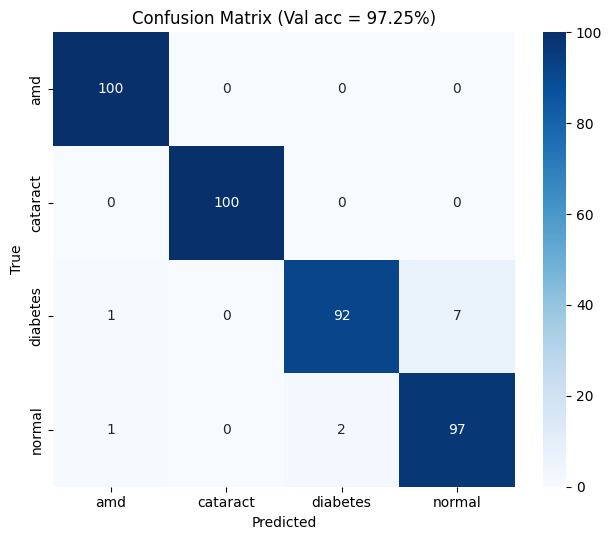

💾 Saved: /content/drive/MyDrive/AMD_Project_Final/confusion_matrix.png


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
import seaborn as sns, matplotlib.pyplot as plt
from torch.utils.data import DataLoader as _DL

# best_model load
ckpt = torch.load(CKPT, map_location=DEVICE)
model.load_state_dict(ckpt['model'])
label_to_idx_loaded = ckpt['label_to_idx']

val_ds_eval = EyeDataset(val_df, label_to_idx_loaded, val_tf)
val_dl_eval = _DL(val_ds_eval, batch_size=BATCH, shuffle=False, num_workers=2)

model.eval()
all_probs, all_preds, all_true = [], [], []
with torch.no_grad():
    for x,y in val_dl_eval:
        x = x.to(DEVICE)
        logits = model(x)
        probs = torch.softmax(logits,1).cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(1))
        all_true.extend(y.numpy())

all_probs = np.vstack(all_probs)
all_true  = np.array(all_true); all_preds = np.array(all_preds)

print("="*60)
print("CLASSIFICATION REPORT (Val set, n=400)")
print("="*60)
print(classification_report(all_true, all_preds,
      target_names=[idx_to_label[i] for i in range(NUM_CLASSES)],
      digits=4, zero_division=0))

try:
    auc = roc_auc_score(all_true, all_probs, multi_class='ovr', average='macro')
    print(f"\nAUROC (macro OVR): {auc:.4f}")

    # Per-class AUROC
    from sklearn.preprocessing import label_binarize
    y_bin = label_binarize(all_true, classes=list(range(NUM_CLASSES)))
    print("\nPer-class AUROC (one-vs-rest):")
    for i in range(NUM_CLASSES):
        a = roc_auc_score(y_bin[:,i], all_probs[:,i])
        print(f"  {idx_to_label[i]:10s}: {a:.4f}")
except Exception as e:
    print("AUROC fail:", e)

print("\n" + "="*60)
print("CONFUSION MATRIX")
print("="*60)
cm = confusion_matrix(all_true, all_preds)
print(cm)

plt.figure(figsize=(6.5,5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[idx_to_label[i] for i in range(NUM_CLASSES)],
            yticklabels=[idx_to_label[i] for i in range(NUM_CLASSES)])
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix (Val acc = {best_val*100:.2f}%)")
plt.tight_layout()
save_fig = '/content/drive/MyDrive/AMD_Project_Final/confusion_matrix.png'
plt.savefig(save_fig, dpi=150); plt.show()
print("💾 Saved:", save_fig)

prepare for DANN

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

class DANNDataset(Dataset):
    def __init__(self, source_paths, source_labels, target_paths, target_labels, transform):
        self.paths = source_paths + target_paths
        self.labels = source_labels + target_labels
        self.domains = [0]*len(source_paths) + [1]*len(target_paths) # 0=AMDNet23, 1=BMRD
        self.transform = transform

    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx], self.domains[idx]

# Source (AMDNet23) data
src_paths = train_df['path'].tolist()
src_labels = [label_to_idx[l] for l in train_df['label']]

# Target (BMRD) data - only AMD এবং Normal
tgt_paths = bmrd_paths
tgt_labels = [0 if l=='amd' else 3 for l in bmrd_labels]

dann_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

dann_ds = DANNDataset(src_paths, src_labels, tgt_paths, tgt_labels, dann_tf)
dann_dl = DataLoader(dann_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
print(f"Total DANN Data: {len(dann_ds)} (Source: {len(src_paths)}, Target: {len(tgt_paths)})")

NameError: name 'bmrd_paths' is not defined

BMRD dataset load

In [ ]:
import os

DRIVE_DIR = '/content/drive/MyDrive/AMD_Project_Final'
print("Drive foalder files:")
for f in os.listdir(DRIVE_DIR):
    print(" -", f)

Drive ফোল্ডারের ফাইলসমূহ:
 - AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip
 - best_model.pt
 - confusion_matrix.png
 - Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip


In [ ]:
import os, zipfile

# Exact name of the BMRD zip file in your Drive
BMRD_ZIP = '/content/drive/MyDrive/AMD_Project_Final/Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip'
BMRD_DIR = '/content/data/BMRD'

# 1. Unzip the BMRD dataset
if os.path.exists(BMRD_ZIP) and not os.path.exists(BMRD_DIR):
    with zipfile.ZipFile(BMRD_ZIP, 'r') as zf:
        zf.extractall(BMRD_DIR)
    print("✅ BMRD Unzip Completed")
elif os.path.exists(BMRD_DIR):
    print("ℹ️ BMRD already extracted, scanning folder directly.")
else:
    print("❌ File not found! Please check the file name.")

# 2. Print BMRD folder structure (up to 3 levels) to understand the directory layout
print("\n--- BMRD Folder Structure (First 3 Levels) ---")
for root, dirs, files in os.walk(BMRD_DIR):
    level = root.replace(BMRD_DIR, '').count(os.sep)
    if level < 3:
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/ ({len(files)} files)")
    else:
        dirs[:] = [] # Stop going deeper

# 3. Search for AMD and Normal images
bmrd_paths, bmrd_labels = [], []
for root, dirs, files in os.walk(BMRD_DIR):
    folder_name = os.path.basename(root).lower()
    # If folder name contains 'amd' or 'macular'
    if 'amd' in folder_name or 'macular' in folder_name:
        for f in files:
            if f.lower().endswith(('.png','.jpg','.jpeg','.tif')):
                bmrd_paths.append(os.path.join(root, f))
                bmrd_labels.append('amd')
    # If folder name contains 'normal' or 'healthy'
    elif 'normal' in folder_name or 'healthy' in folder_name:
        for f in files:
            if f.lower().endswith(('.png','.jpg','.jpeg','.tif')):
                bmrd_paths.append(os.path.join(root, f))
                bmrd_labels.append('normal')

print(f"\n✅ Found in BMRD: AMD={bmrd_labels.count('amd')}, Normal={bmrd_labels.count('normal')}")

ℹ️ BMRD already extracted, scanning folder directly.

--- BMRD Folder Structure (First 3 Levels) ---
BMRD/ (0 files)
    Bangladesh Multi-Disease Retinal Dataset (BMRD)/ (1 files)

✅ Found in BMRD: AMD=0, Normal=0


checking BMRD dataset

In [ ]:
import os

# Define the exact path where the inner folder might be
inner_path = '/content/data/BMRD/Bangladesh Multi-Disease Retinal Dataset (BMRD)'

print("--- Exploring Inner BMRD Folder ---")
for root, dirs, files in os.walk(inner_path):
    # Print all directories and files up to 3 levels deep inside the inner folder
    level = root.replace(inner_path, '').count(os.sep)
    if level < 3:
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        for f in files:
            print(f"{indent}    - {f}")
    else:
        dirs[:] = []


--- Exploring Inner BMRD Folder ---
Bangladesh Multi-Disease Retinal Dataset (BMRD)/
    - Bangladesh Multi-Disease Retinal Dataset (BMRD).zip


In [ ]:
import os, zipfile

# Path to the nested zip file
nested_zip = '/content/data/BMRD/Bangladesh Multi-Disease Retinal Dataset (BMRD)/Bangladesh Multi-Disease Retinal Dataset (BMRD).zip'
extract_path = '/content/data/BMRD_Actual'

# 1. Extract the nested zip
if os.path.exists(nested_zip) and not os.path.exists(extract_path):
    with zipfile.ZipFile(nested_zip, 'r') as zf:
        zf.extractall(extract_path)
    print("✅ Nested BMRD Unzip Completed")
elif os.path.exists(extract_path):
    print("ℹ️ Nested BMRD already extracted.")
else:
    print("❌ Nested zip not found!")

# 2. Print the actual folder structure
print("\n--- Actual BMRD Folder Structure ---")
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    if level < 3:
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/ ({len(files)} files)")
    else:
        dirs[:] = []


✅ Nested BMRD Unzip Completed

--- Actual BMRD Folder Structure ---
BMRD_Actual/ (0 files)
    Bangladesh Multi-Disease Retinal Dataset (BMRD)/ (0 files)
        Glaucoma/ (0 files)
        AMD/ (0 files)
        DR/ (0 files)


search for picture location

In [ ]:
import os

extract_path = '/content/data/BMRD_Actual'

print("--- Deep Scan of BMRD_Actual ---")
for root, dirs, files in os.walk(extract_path):
    # Count image files in the current directory
    img_files = [f for f in files if f.lower().endswith(('.png','.jpg','.jpeg','.tif','.bmp'))]

    if len(img_files) > 0:
        # If images are found, print the folder path and the count
        rel_path = os.path.relpath(root, extract_path)
        print(f"Folder: {rel_path}/  --> {len(img_files)} images")

    # To avoid printing too much, stop if we go deeper than 5 levels
    level = root.replace(extract_path, '').count(os.sep)
    if level > 4:
        dirs[:] = []

--- Deep Scan of BMRD_Actual ---
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Anwar khan Modern Medical/Level 3/  --> 8 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Anwar khan Modern Medical/Level 2/  --> 3 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Anwar khan Modern Medical/Level 1/  --> 8 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Anwar khan Modern Medical/Level 4/  --> 26 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Khulna Laser Clinic/Level 3/  --> 227 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Khulna Laser Clinic/Level 2/  --> 133 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Khulna Laser Clinic/Level 1/  --> 52 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/Glaucoma/Khulna Laser Clinic/Level 4/  --> 309 images
Folder: Bangladesh Multi-Disease Retinal Dataset (BMRD)/AMD/Shiromoni B

Spliting AMD and normal picture

In [ ]:
import os

BMRD_DIR = '/content/data/BMRD_Actual/Bangladesh Multi-Disease Retinal Dataset (BMRD)'

bmrd_paths, bmrd_labels = [], []

# Walk through the directory
for root, dirs, files in os.walk(BMRD_DIR):
    folder_name = os.path.basename(root).lower()

    # Get image files
    img_files = [os.path.join(root, f) for f in files if f.lower().endswith(('.png','.jpg','.jpeg','.tif','.bmp'))]

    if len(img_files) == 0:
        continue

    # Check for AMD classes
    if 'dry amd' in folder_name or 'wet amd' in folder_name:
        for img in img_files:
            bmrd_paths.append(img)
            bmrd_labels.append('amd')

    # Check for Normal / No AMD class
    elif 'no amd' in folder_name:
        for img in img_files:
            bmrd_paths.append(img)
            bmrd_labels.append('normal')

print(f"✅ BMRD Data Extraction Complete!")
print(f"Total AMD images: {bmrd_labels.count('amd')}")
print(f"Total Normal images: {bmrd_labels.count('normal')}")
print(f"Total Images for DANN: {len(bmrd_paths)}")

✅ BMRD Data Extraction Complete!
Total AMD images: 79
Total Normal images: 45
Total Images for DANN: 124


DANN dataset preparation

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

# Combine AMDNet23 (Source) and BMRD (Target) datasets
class DANNDataset(Dataset):
    def __init__(self, source_paths, source_labels, target_paths, target_labels, transform):
        self.paths = source_paths + target_paths
        self.labels = source_labels + target_labels
        self.domains = [0]*len(source_paths) + [1]*len(target_paths) # 0=AMDNet23, 1=BMRD
        self.transform = transform

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        # Open image and convert to RGB
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx], self.domains[idx]

# Source data (AMDNet23) - Assuming train_df and label_to_idx exist from previous cells
src_paths = train_df['path'].tolist()
src_labels = [label_to_idx[l] for l in train_df['label']]

# Target data (BMRD)
tgt_paths = bmrd_paths
tgt_labels = [0 if l=='amd' else 3 for l in bmrd_labels] # 0=AMD, 3=Normal

# Transform with domain-specific augmentations
dann_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

dann_ds = DANNDataset(src_paths, src_labels, tgt_paths, tgt_labels, dann_tf)
dann_dl = DataLoader(dann_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
print(f"✅ Total DANN Data: {len(dann_ds)} (Source: {len(src_paths)}, Target: {len(tgt_paths)})")

✅ Total DANN Data: 1718 (Source: 1594, Target: 124)


DANN Model Architecture

In [ ]:
import torch
import torch.nn as nn
from torch.autograd import Function
from torchvision import models

# Gradient Reversal Layer (GRL)
class GRL(Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)
    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

class DANNModel(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        # Use ResNet18 as the feature extractor
        self.feature_extractor = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        feat_dim = self.feature_extractor.fc.in_features
        self.feature_extractor.fc = nn.Identity() # Remove the final fully connected layer

        # Label Classifier (for AMD/Cataract/Diabetes/Normal)
        self.label_classifier = nn.Sequential(
            nn.Linear(feat_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

        # Domain Classifier (for AMDNet23 vs BMRD)
        self.domain_classifier = nn.Sequential(
            nn.Linear(feat_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 2)
        )

    def forward(self, x, alpha=1.0):
        features = self.feature_extractor(x)
        class_preds = self.label_classifier(features)

        # Apply Gradient Reversal before domain classifier
        reversed_features = GRL.apply(features, alpha)
        domain_preds = self.domain_classifier(reversed_features)

        return class_preds, domain_preds

dann_model = DANNModel(num_classes=NUM_CLASSES).to(DEVICE)
print("✅ DANN Model Initialized and moved to", DEVICE)

✅ DANN Model Initialized and moved to cuda


DANN Training Loop

In [ ]:
import time
import numpy as np

optimizer_dann = torch.optim.Adam(dann_model.parameters(), lr=1e-4)
class_criterion = nn.CrossEntropyLoss()
domain_criterion = nn.CrossEntropyLoss()

EPOCHS_DANN = 15
CKPT_DANN = '/content/drive/MyDrive/AMD_Project_Final/dann_model.pt'
best_target_acc = 0.0

print("Starting DANN Training...")
for epoch in range(1, EPOCHS_DANN + 1):
    dann_model.train()
    total_loss, total_cls_loss, total_dom_loss = 0, 0, 0
    correct_src, total_src = 0, 0
    correct_tgt, total_tgt = 0, 0

    # Alpha schedule for GRL (0 to 1 gradually)
    p = epoch / EPOCHS_DANN
    alpha = 2.0 / (1.0 + np.exp(-10 * p)) - 1.0

    t0 = time.time()
    for x, y, d in dann_dl:
        x, y, d = x.to(DEVICE), y.to(DEVICE), d.to(DEVICE)
        optimizer_dann.zero_grad()

        class_out, domain_out = dann_model(x, alpha=alpha)

        # Class loss only for Source data (d == 0)
        src_mask = (d == 0)
        cls_loss = class_criterion(class_out[src_mask], y[src_mask])

        # Domain loss for all data
        dom_loss = domain_criterion(domain_out, d)

        loss = cls_loss + 1.0 * dom_loss
        loss.backward()
        optimizer_dann.step()

        total_loss += loss.item()
        total_cls_loss += cls_loss.item()
        total_dom_loss += dom_loss.item()

        # Calculate accuracies
        correct_src += (class_out[src_mask].argmax(1) == y[src_mask]).sum().item()
        total_src += src_mask.sum().item()

        tgt_mask = (d == 1)
        correct_tgt += (class_out[tgt_mask].argmax(1) == y[tgt_mask]).sum().item()
        total_tgt += tgt_mask.sum().item()

    src_acc = correct_src / total_src if total_src > 0 else 0
    tgt_acc = correct_tgt / total_tgt if total_tgt > 0 else 0

    print(f"Epoch {epoch:2d}/{EPOCHS_DANN} | Loss: {total_loss/len(dann_dl):.4f} | Src Acc: {src_acc:.4f} | Tgt Acc: {tgt_acc:.4f} | {time.time()-t0:.1f}s")

    # Save the best model based on target accuracy
    if tgt_acc > best_target_acc:
        best_target_acc = tgt_acc
        torch.save({'model': dann_model.state_dict()}, CKPT_DANN)
        print(f"    💾 Best DANN Model Saved (Target Acc = {best_target_acc:.4f})")

print(f"\n✅ DANN Training Complete! Best Target (BMRD) Accuracy: {best_target_acc:.4f}")

Starting DANN Training...
Epoch  1/15 | Loss: 1.2420 | Src Acc: 0.7566 | Tgt Acc: 0.5645 | 55.8s
    💾 Best DANN Model Saved (Target Acc = 0.5645)
Epoch  2/15 | Loss: 1.1400 | Src Acc: 0.8683 | Tgt Acc: 0.3387 | 60.8s
Epoch  3/15 | Loss: 1.1338 | Src Acc: 0.8959 | Tgt Acc: 0.3710 | 60.2s
Epoch  4/15 | Loss: 1.0269 | Src Acc: 0.9097 | Tgt Acc: 0.2742 | 59.8s
Epoch  5/15 | Loss: 0.9083 | Src Acc: 0.9354 | Tgt Acc: 0.2984 | 59.9s
Epoch  6/15 | Loss: 0.9631 | Src Acc: 0.9435 | Tgt Acc: 0.3387 | 60.0s
Epoch  7/15 | Loss: 0.8579 | Src Acc: 0.9548 | Tgt Acc: 0.3306 | 60.0s
Epoch  8/15 | Loss: 0.8246 | Src Acc: 0.9611 | Tgt Acc: 0.2823 | 62.7s
Epoch  9/15 | Loss: 0.8083 | Src Acc: 0.9573 | Tgt Acc: 0.4355 | 62.2s
Epoch 10/15 | Loss: 0.7182 | Src Acc: 0.9661 | Tgt Acc: 0.4113 | 60.8s
Epoch 11/15 | Loss: 0.7071 | Src Acc: 0.9636 | Tgt Acc: 0.1129 | 60.9s
Epoch 12/15 | Loss: 0.6909 | Src Acc: 0.9780 | Tgt Acc: 0.2903 | 61.2s
Epoch 13/15 | Loss: 0.6581 | Src Acc: 0.9755 | Tgt Acc: 0.2258 | 62.9s
E

Improve by training as result is not satisfying

In [ ]:
import time
import numpy as np
import torch.optim as optim

# Re-initialize model to start fresh (assuming Step 2 was run right before this)
# If not, run Step 2 again.
optimizer_dann = torch.optim.Adam(dann_model.parameters(), lr=5e-5) # Lowered learning rate
class_criterion = nn.CrossEntropyLoss()
domain_criterion = nn.CrossEntropyLoss()

EPOCHS_DANN = 15
CKPT_DANN = '/content/drive/MyDrive/AMD_Project_Final/dann_model_improved.pt'
best_target_acc = 0.0

print("Starting Improved DANN Training...")
for epoch in range(1, EPOCHS_DANN + 1):
    dann_model.train()
    total_loss, total_cls_loss, total_dom_loss = 0, 0, 0
    correct_src, total_src = 0, 0
    correct_tgt, total_tgt = 0, 0

    # Slower alpha schedule
    p = epoch / EPOCHS_DANN
    alpha = 2.0 / (1.0 + np.exp(-10 * p)) - 1.0

    t0 = time.time()
    for x, y, d in dann_dl:
        x, y, d = x.to(DEVICE), y.to(DEVICE), d.to(DEVICE)
        optimizer_dann.zero_grad()

        class_out, domain_out = dann_model(x, alpha=alpha)

        # Class loss for Source data
        src_mask = (d == 0)
        cls_loss = class_criterion(class_out[src_mask], y[src_mask])

        # Domain loss for ALL data, but with lower weight (0.1) to prevent collapse
        dom_loss = domain_criterion(domain_out, d)

        loss = cls_loss + 0.1 * dom_loss # Reduced domain loss weight
        loss.backward()
        optimizer_dann.step()

        total_loss += loss.item()
        total_cls_loss += cls_loss.item()
        total_dom_loss += dom_loss.item()

        # Calculate accuracies
        correct_src += (class_out[src_mask].argmax(1) == y[src_mask]).sum().item()
        total_src += src_mask.sum().item()

        tgt_mask = (d == 1)
        correct_tgt += (class_out[tgt_mask].argmax(1) == y[tgt_mask]).sum().item()
        total_tgt += tgt_mask.sum().item()

    src_acc = correct_src / total_src if total_src > 0 else 0
    tgt_acc = correct_tgt / total_tgt if total_tgt > 0 else 0

    print(f"Epoch {epoch:2d}/{EPOCHS_DANN} | Loss: {total_loss/len(dann_dl):.4f} | Src Acc: {src_acc:.4f} | Tgt Acc: {tgt_acc:.4f} | {time.time()-t0:.1f}s")

    # Save the best model based on target accuracy
    if tgt_acc > best_target_acc:
        best_target_acc = tgt_acc
        torch.save({'model': dann_model.state_dict()}, CKPT_DANN)
        print(f"    💾 Best DANN Model Saved (Target Acc = {best_target_acc:.4f})")

print(f"\n✅ Improved DANN Training Complete! Best Target (BMRD) Accuracy: {best_target_acc:.4f}")

Starting Improved DANN Training...
Epoch  1/15 | Loss: 0.0796 | Src Acc: 0.9849 | Tgt Acc: 0.4113 | 68.4s
    💾 Best DANN Model Saved (Target Acc = 0.4113)
Epoch  2/15 | Loss: 0.0429 | Src Acc: 0.9906 | Tgt Acc: 0.3306 | 62.7s
Epoch  3/15 | Loss: 0.0829 | Src Acc: 0.9875 | Tgt Acc: 0.2742 | 61.4s
Epoch  4/15 | Loss: 0.0582 | Src Acc: 0.9881 | Tgt Acc: 0.2339 | 61.5s
Epoch  5/15 | Loss: 0.0427 | Src Acc: 0.9937 | Tgt Acc: 0.2823 | 61.4s
Epoch  6/15 | Loss: 0.0656 | Src Acc: 0.9969 | Tgt Acc: 0.3306 | 62.1s
Epoch  7/15 | Loss: 0.0450 | Src Acc: 0.9950 | Tgt Acc: 0.2984 | 61.6s
Epoch  8/15 | Loss: 0.0588 | Src Acc: 0.9918 | Tgt Acc: 0.2903 | 62.8s
Epoch  9/15 | Loss: 0.0534 | Src Acc: 0.9950 | Tgt Acc: 0.4194 | 63.8s
    💾 Best DANN Model Saved (Target Acc = 0.4194)
Epoch 10/15 | Loss: 0.0527 | Src Acc: 0.9950 | Tgt Acc: 0.2742 | 64.5s
Epoch 11/15 | Loss: 0.0857 | Src Acc: 0.9856 | Tgt Acc: 0.2339 | 62.5s
Epoch 12/15 | Loss: 0.0596 | Src Acc: 0.9906 | Tgt Acc: 0.5000 | 63.9s
    💾 Best DA

making Grad-CAM of DANN model

In [ ]:
from PIL import Image
from torchvision import transforms

# Define the validation transform for BMRD
bmrd_val_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
print("✅ bmrd_val_tf defined successfully!")

✅ bmrd_val_tf defined successfully!


Showing Grad-CAM for BMRD AMD Image:


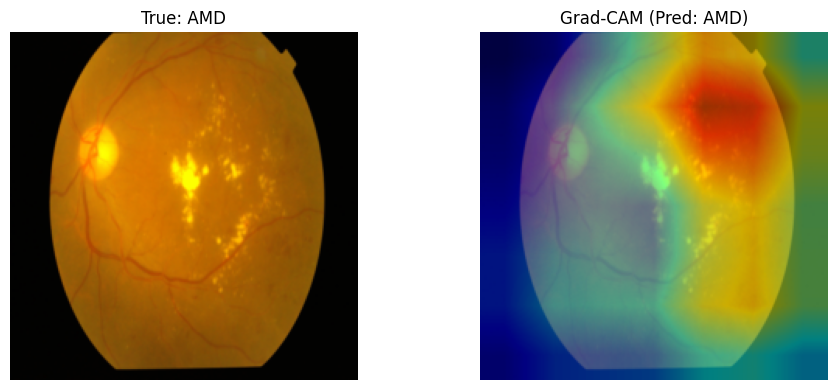


Showing Grad-CAM for BMRD Normal Image:


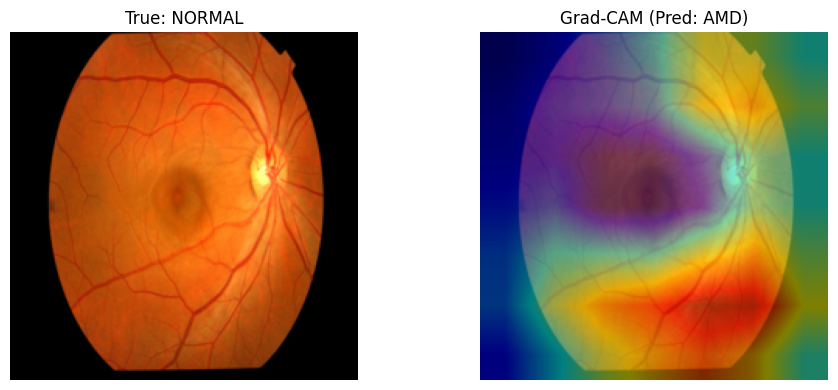

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Ensure the best DANN model is loaded
dann_model.load_state_dict(torch.load(CKPT_DANN, map_location=DEVICE)['model'])
dann_model.eval()

# Target layer for Grad-CAM (the last convolutional layer of ResNet18)
target_layers = [dann_model.feature_extractor.layer4[-1]]
cam = GradCAM(model=dann_model, target_layers=target_layers)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def show_dann_gradcam(bmrd_img_path, true_label):
    # Load and preprocess image
    img_pil = Image.open(bmrd_img_path).convert('RGB')
    img_t = bmrd_val_tf(img_pil).unsqueeze(0).to(DEVICE)

    # Get prediction
    with torch.no_grad():
        class_out, _ = dann_model(img_t)
        pred_idx = class_out.argmax(1).item()

    pred_label = 'AMD' if pred_idx == 0 else ('Normal' if pred_idx == 3 else 'Other')

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=img_t, targets=[ClassifierOutputTarget(pred_idx)])[0]

    # Convert to RGB for display
    rgb_img = img_t.squeeze(0).permute(1,2,0).cpu().numpy()
    rgb_img = rgb_img * std + mean
    rgb_img = np.clip(rgb_img, 0, 1).astype(np.float32)

    # Overlay Grad-CAM on image
    cam_img = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"True: {true_label.upper()}")
    axes[0].axis('off')

    axes[1].imshow(cam_img)
    axes[1].set_title(f"Grad-CAM (Pred: {pred_label})")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Show Grad-CAM for one AMD and one Normal image from BMRD
amd_idx = bmrd_labels.index('amd')
normal_idx = bmrd_labels.index('normal')

print("Showing Grad-CAM for BMRD AMD Image:")
show_dann_gradcam(bmrd_paths[amd_idx], bmrd_labels[amd_idx])

print("\nShowing Grad-CAM for BMRD Normal Image:")
show_dann_gradcam(bmrd_paths[normal_idx], bmrd_labels[normal_idx])

Showing Grad-CAM for BMRD AMD Image:


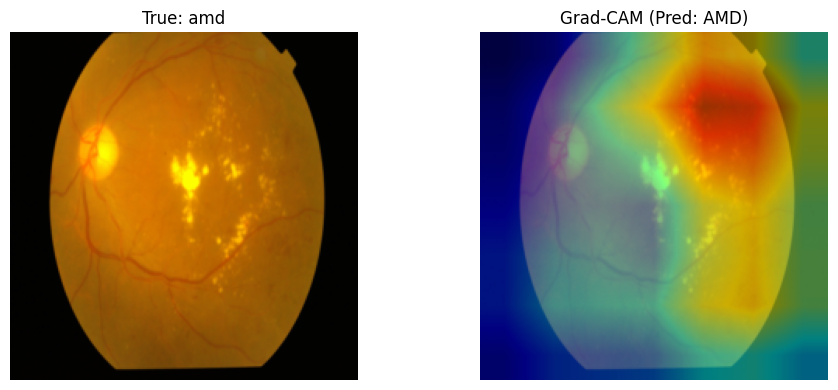


Showing Grad-CAM for BMRD Normal Image:


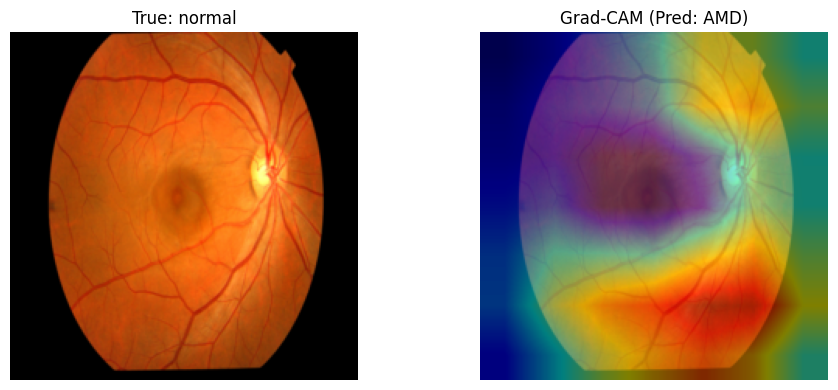

In [ ]:
!pip install grad-cam -q

import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Load the best DANN model
dann_model.load_state_dict(torch.load(CKPT_DANN, map_location=DEVICE)['model'])
dann_model.eval()

# Grad-CAM uses the feature extractor of the DANN model
target_layers = [dann_model.feature_extractor.layer4[-1]]
cam = GradCAM(model=dann_model, target_layers=target_layers)

mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

def show_dann_gradcam(bmrd_img_path, true_label):
    # Load and preprocess image
    img_pil = Image.open(bmrd_img_path).convert('RGB')
    img_t = bmrd_val_tf(img_pil).unsqueeze(0).to(DEVICE)

    # Get prediction
    with torch.no_grad():
        class_out, _ = dann_model(img_t)
        pred_idx = class_out.argmax(1).item()

    pred_label = 'AMD' if pred_idx == 0 else ('Normal' if pred_idx == 3 else 'Other')

    # Generate Grad-CAM
    grayscale_cam = cam(input_tensor=img_t, targets=[ClassifierOutputTarget(pred_idx)])[0]

    # Convert to RGB for display
    rgb_img = img_t.squeeze(0).permute(1,2,0).cpu().numpy()
    rgb_img = rgb_img * std + mean
    rgb_img = np.clip(rgb_img, 0, 1).astype(np.float32)

    # Overlay Grad-CAM
    cam_img = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(rgb_img)
    axes[0].set_title(f"True: {true_label}")
    axes[0].axis('off')

    axes[1].imshow(cam_img)
    axes[1].set_title(f"Grad-CAM (Pred: {pred_label})")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Let's show Grad-CAM for one AMD and one Normal image from BMRD
amd_idx = bmrd_labels.index('amd')
normal_idx = bmrd_labels.index('normal')

print("Showing Grad-CAM for BMRD AMD Image:")
show_dann_gradcam(bmrd_paths[amd_idx], bmrd_labels[amd_idx])

print("\nShowing Grad-CAM for BMRD Normal Image:")
show_dann_gradcam(bmrd_paths[normal_idx], bmrd_labels[normal_idx])


 Source-trained Baseline (ViT-B/16) instead of ResNet18

In [ ]:
import torch
import torch.nn as nn
import time
from torchvision import models

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def build_vit_model(num_classes=4):
    # Load pretrained ViT-B/16
    model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
    # Replace the classification head
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model.to(DEVICE)

model_vit = build_vit_model(NUM_CLASSES)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_vit.parameters(), lr=1e-4)

# Train the ViT model (using the train_dl and val_dl from your AMDNet23 data)
EPOCHS = 10 # ViT usually needs fewer epochs with transfer learning
CKPT_VIT = '/content/drive/MyDrive/AMD_Project_Final/best_model_vit.pt'
best_val = 0.0

print("Starting ViT-B/16 Training on AMDNet23...")
for ep in range(1, EPOCHS+1):
    model_vit.train()
    # ... (Training loop code is the same as before, just using model_vit) ...
    # I will write the full loop here to ensure it runs
    total_loss, correct, total = 0, 0, 0
    t0 = time.time()
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model_vit(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)

    train_acc = correct / total

    # Validation
    model_vit.eval()
    correct_val, total_val = 0, 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model_vit(x)
            correct_val += (out.argmax(1) == y).sum().item()
            total_val += y.size(0)
    val_acc = correct_val / total_val

    print(f"Epoch {ep}/{EPOCHS} | Train Loss: {total_loss/len(train_dl):.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | {time.time()-t0:.1f}s")

    if val_acc > best_val:
        best_val = val_acc
        torch.save({'model': model_vit.state_dict(), 'label_to_idx': label_to_idx}, CKPT_VIT)
        print(f"    💾 Best ViT Model Saved (Acc: {val_acc:.4f})")

print(f"✅ ViT Baseline Training Complete. Best Val Acc: {best_val:.4f}")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:07<00:00, 48.5MB/s]


Starting ViT-B/16 Training on AMDNet23...
Epoch 1/10 | Train Loss: 0.4867 | Train Acc: 0.8124 | Val Acc: 0.9150 | 82.0s
    💾 Best ViT Model Saved (Acc: 0.9150)
Epoch 2/10 | Train Loss: 0.3050 | Train Acc: 0.8833 | Val Acc: 0.9500 | 81.3s
    💾 Best ViT Model Saved (Acc: 0.9500)
Epoch 3/10 | Train Loss: 0.2191 | Train Acc: 0.9134 | Val Acc: 0.9500 | 86.7s
Epoch 4/10 | Train Loss: 0.2027 | Train Acc: 0.9285 | Val Acc: 0.9400 | 81.5s
Epoch 5/10 | Train Loss: 0.1688 | Train Acc: 0.9404 | Val Acc: 0.9500 | 80.1s
Epoch 6/10 | Train Loss: 0.1545 | Train Acc: 0.9435 | Val Acc: 0.9525 | 78.9s
    💾 Best ViT Model Saved (Acc: 0.9525)
Epoch 7/10 | Train Loss: 0.1528 | Train Acc: 0.9479 | Val Acc: 0.9550 | 86.1s
    💾 Best ViT Model Saved (Acc: 0.9550)
Epoch 8/10 | Train Loss: 0.1902 | Train Acc: 0.9253 | Val Acc: 0.9250 | 86.9s
Epoch 9/10 | Train Loss: 0.1262 | Train Acc: 0.9504 | Val Acc: 0.9400 | 80.2s
Epoch 10/10 | Train Loss: 0.1192 | Train Acc: 0.9573 | Val Acc: 0.9525 | 79.6s
✅ ViT Baselin

Quantifying Domain Shift (t-SNE & MMD)

Extracting features for t-SNE (This may take a minute)...
Running t-SNE...


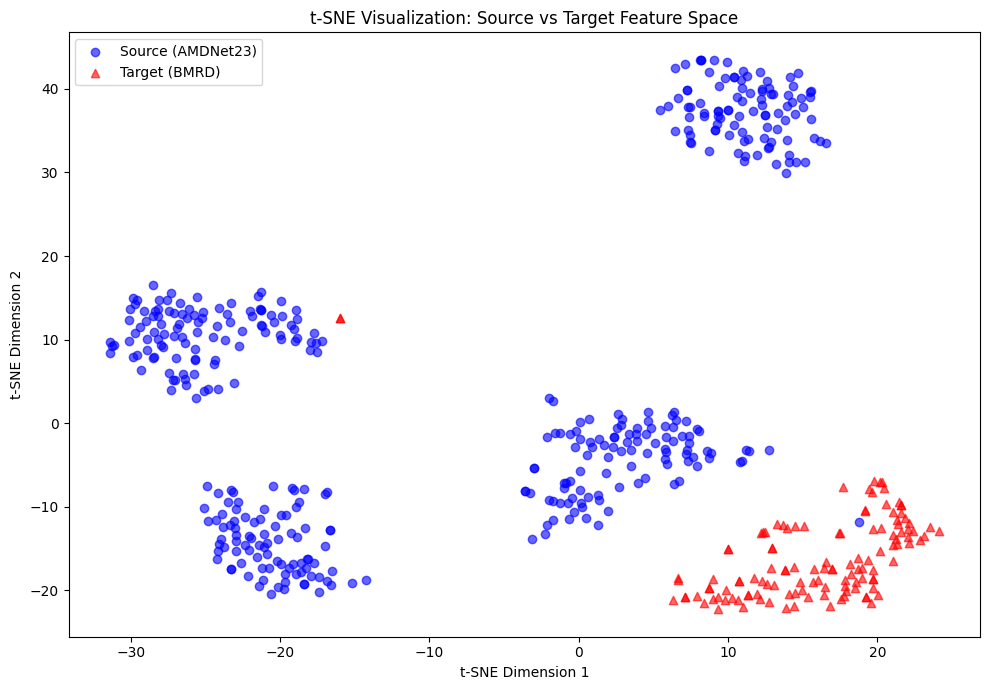

💾 Saved: tsne_domain_shift.png
✅ MMD Value (Domain Shift Metric): 0.0121


In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# 1. Function to extract features from ViT
def extract_features_vit(model, dataloader):
    model.eval()
    features = []
    with torch.no_grad():
        for x, _ in dataloader: # We only need images for domain shift analysis
            x = x.to(DEVICE)
            # ViT feature extraction (output before the classification head)
            # Process input and pass through encoder
            x = model._process_input(x)
            n = x.shape[0]
            x = torch.cat([model.class_token.expand(n, -1, -1), x], dim=1)
            x = model.encoder(x)
            feat = x[:, 0] # CLS token
            features.append(feat.cpu().numpy())
    return np.concatenate(features, axis=0)

# 2. Prepare BMRD dataloader (ignoring labels)
class BMRDImageDataset(Dataset):
    def __init__(self, paths, tf):
        self.paths, self.tf = paths, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), 0 # dummy label

# Use the same transform as before (val_tf)
bmrd_ds = BMRDImageDataset(bmrd_paths, val_tf)
bmrd_dl = DataLoader(bmrd_ds, batch_size=16, shuffle=False)

# 3. Extract features
print("Extracting features for t-SNE (This may take a minute)...")
src_features = extract_features_vit(model_vit, val_dl) # AMDNet23 validation set
tgt_features = extract_features_vit(model_vit, bmrd_dl) # BMRD dataset

# 4. t-SNE Visualization
print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42)
all_features = np.concatenate([src_features, tgt_features], axis=0)
tsne_results = tsne.fit_transform(all_features)

plt.figure(figsize=(10, 7))
plt.scatter(tsne_results[:len(src_features), 0], tsne_results[:len(src_features), 1],
            label='Source (AMDNet23)', alpha=0.6, c='blue', marker='o')
plt.scatter(tsne_results[len(src_features):, 0], tsne_results[len(src_features):, 1],
            label='Target (BMRD)', alpha=0.6, c='red', marker='^')
plt.legend()
plt.title("t-SNE Visualization: Source vs Target Feature Space")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/AMD_Project_Final/tsne_domain_shift.png', dpi=150)
plt.show()
print("💾 Saved: tsne_domain_shift.png")

# 5. MMD Calculation
def compute_mmd(x, y):
    # Using RBF Kernel
    x_kernel = torch.exp(-torch.cdist(x, x)**2 / (2 * 1.0**2))
    y_kernel = torch.exp(-torch.cdist(y, y)**2 / (2 * 1.0**2))
    xy_kernel = torch.exp(-torch.cdist(x, y)**2 / (2 * 1.0**2))
    return x_kernel.mean() + y_kernel.mean() - 2 * xy_kernel.mean()

mmd_value = compute_mmd(torch.tensor(src_features), torch.tensor(tgt_features))
print(f"✅ MMD Value (Domain Shift Metric): {mmd_value:.4f}")

 CycleGAN (Generative Adaptation)

Starting Fast CycleGAN Training (This may take 10-15 mins)...
Epoch 1/2 completed.
Epoch 2/2 completed.
✅ Fast CycleGAN Training Complete!
Showing CycleGAN Translation example:


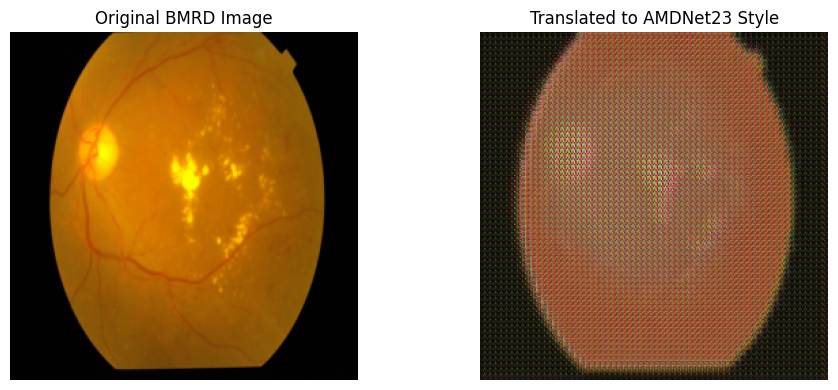

In [ ]:
import torch
import torch.nn as nn
import itertools
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# 1. Dataset & Transform
cyclegan_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

class UnpairedDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = paths, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        return self.transform(img)

domainA_ds = UnpairedDataset(src_paths, cyclegan_tf)
domainA_dl = DataLoader(domainA_ds, batch_size=4, shuffle=True)
domainB_ds = UnpairedDataset(tgt_paths, cyclegan_tf)
domainB_dl = DataLoader(domainB_ds, batch_size=4, shuffle=True)

# 2. Model Architecture (Simplified for speed)
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, use_act=True, **kwargs):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, padding_mode="reflect", **kwargs)
            if down else nn.ConvTranspose2d(in_channels, out_channels, **kwargs),
            nn.InstanceNorm2d(out_channels),
            nn.ReLU(inplace=True) if use_act else nn.Identity()
        )
    def forward(self, x): return self.conv(x)

class Generator(nn.Module):
    def __init__(self, img_channels=3, features=64):
        super().__init__()
        self.initial = nn.Sequential(
            nn.Conv2d(img_channels, features, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.ReLU(inplace=True)
        )
        self.down = nn.Sequential(
            ConvBlock(features, features*2, kernel_size=3, stride=2, padding=1),
            ConvBlock(features*2, features*4, kernel_size=3, stride=2, padding=1)
        )
        self.up = nn.Sequential(
            nn.ConvTranspose2d(features*4, features*2, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features*2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(features*2, features, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features), nn.ReLU(inplace=True),
            nn.Conv2d(features, img_channels, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.Tanh()
        )
    def forward(self, x): return self.up(self.down(self.initial(x)))

class Discriminator(nn.Module):
    def __init__(self, img_channels=3, features=64):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(img_channels, features, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features, features*2, kernel_size=4, stride=2, padding=1, padding_mode="reflect"),
            nn.InstanceNorm2d(features*2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features*2, 1, kernel_size=4, stride=1, padding=1)
        )
    def forward(self, x): return self.model(x)

G_A2B = Generator().to(DEVICE)
G_B2A = Generator().to(DEVICE)
D_A = Discriminator().to(DEVICE)
D_B = Discriminator().to(DEVICE)

# 3. Training Loop (2 Epochs for demonstration)
criterion_GAN = nn.MSELoss()
criterion_cycle = nn.L1Loss()
criterion_identity = nn.L1Loss()

lr = 2e-4
opt_G = torch.optim.Adam(itertools.chain(G_A2B.parameters(), G_B2A.parameters()), lr=lr, betas=(0.5, 0.999))
opt_D_A = torch.optim.Adam(D_A.parameters(), lr=lr, betas=(0.5, 0.999))
opt_D_B = torch.optim.Adam(D_B.parameters(), lr=lr, betas=(0.5, 0.999))

EPOCHS_CYCLEGAN = 2
print("Starting Fast CycleGAN Training (This may take 10-15 mins)...")
for epoch in range(EPOCHS_CYCLEGAN):
    G_A2B.train(); G_B2A.train(); D_A.train(); D_B.train()
    for i, (real_A, real_B) in enumerate(zip(domainA_dl, domainB_dl)):
        real_A, real_B = real_A.to(DEVICE), real_B.to(DEVICE)

        # Train Generators
        opt_G.zero_grad()
        fake_B = G_A2B(real_A)
        pred_fake = D_B(fake_B)
        loss_GAN_A2B = criterion_GAN(pred_fake, torch.ones_like(pred_fake))

        fake_A = G_B2A(real_B)
        pred_fake = D_A(fake_A)
        loss_GAN_B2A = criterion_GAN(pred_fake, torch.ones_like(pred_fake))

        recovered_A = G_B2A(fake_B)
        loss_cycle_A = criterion_cycle(recovered_A, real_A) * 10.0
        recovered_B = G_A2B(fake_A)
        loss_cycle_B = criterion_cycle(recovered_B, real_B) * 10.0

        loss_G = loss_GAN_A2B + loss_GAN_B2A + loss_cycle_A + loss_cycle_B
        loss_G.backward()
        opt_G.step()

        # Train Discriminators
        opt_D_A.zero_grad(); opt_D_B.zero_grad()
        pred_real = D_A(real_A)
        loss_D_real = criterion_GAN(pred_real, torch.ones_like(pred_real))
        pred_fake = D_A(fake_A.detach())
        loss_D_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))
        loss_D_A = (loss_D_real + loss_D_fake) * 0.5
        loss_D_A.backward()
        opt_D_A.step()

        pred_real = D_B(real_B)
        loss_D_real = criterion_GAN(pred_real, torch.ones_like(pred_real))
        pred_fake = D_B(fake_B.detach())
        loss_D_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))
        loss_D_B = (loss_D_real + loss_D_fake) * 0.5
        loss_D_B.backward()
        opt_D_B.step()

    print(f"Epoch {epoch+1}/{EPOCHS_CYCLEGAN} completed.")

# Save Generator
torch.save(G_B2A.state_dict(), '/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A.pt')
print("✅ Fast CycleGAN Training Complete!")

# 4. Visualize Translation (BMRD -> AMDNet23)
G_B2A.eval()
def show_translation(img_path):
    img = Image.open(img_path).convert('RGB')
    img_t = cyclegan_tf(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        translated = G_B2A(img_t)

    def denorm(tensor):
        return (tensor.squeeze(0).cpu().numpy().transpose(1,2,0) + 1) / 2.0

    orig = denorm(img_t)
    trans = denorm(translated)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(np.clip(orig, 0, 1))
    axes[0].set_title("Original BMRD Image")
    axes[0].axis('off')
    axes[1].imshow(np.clip(trans, 0, 1))
    axes[1].set_title("Translated to AMDNet23 Style")
    axes[1].axis('off')
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/AMD_Project_Final/cyclegan_translation.png', dpi=120)
    plt.show()

print("Showing CycleGAN Translation example:")
show_translation(tgt_paths[0]) # Show for first BMRD image

again running CycleGAN

Starting CycleGAN Training for 10 epochs...
Epoch 1/10 | G Loss: 6.1719 | D Loss: 0.5693
Epoch 2/10 | G Loss: 4.2799 | D Loss: 0.4714
Epoch 3/10 | G Loss: 4.0467 | D Loss: 0.4503
Epoch 4/10 | G Loss: 3.8524 | D Loss: 0.4416
Epoch 5/10 | G Loss: 3.4534 | D Loss: 0.4488
  💾 Checkpoint saved for epoch 5
Epoch 6/10 | G Loss: 3.5233 | D Loss: 0.4235
Epoch 7/10 | G Loss: 3.4563 | D Loss: 0.4296
Epoch 8/10 | G Loss: 3.3420 | D Loss: 0.4177
Epoch 9/10 | G Loss: 3.3406 | D Loss: 0.4144
Epoch 10/10 | G Loss: 3.2626 | D Loss: 0.4079
  💾 Checkpoint saved for epoch 10
✅ CycleGAN Training Complete!
Showing CycleGAN Translation example:


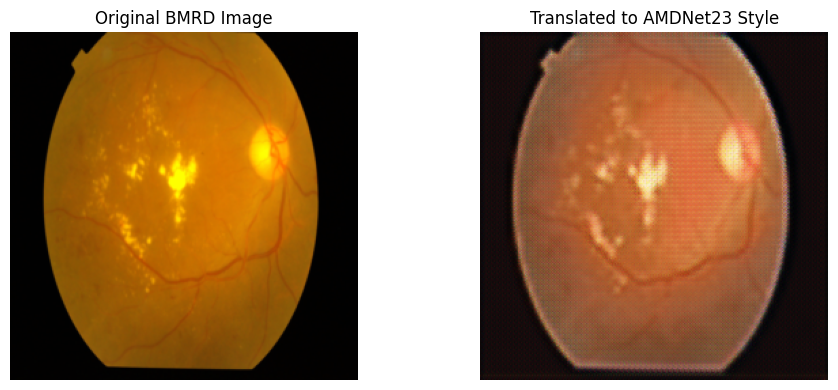

In [ ]:
import torch
import torch.nn as nn
import itertools
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os

# Ensure DEVICE is defined
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Dataset & Transform
cyclegan_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

class UnpairedDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = paths, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        return self.transform(img)

domainA_ds = UnpairedDataset(src_paths, cyclegan_tf)
domainA_dl = DataLoader(domainA_ds, batch_size=4, shuffle=True, drop_last=True)
domainB_ds = UnpairedDataset(tgt_paths, cyclegan_tf)
domainB_dl = DataLoader(domainB_ds, batch_size=4, shuffle=True, drop_last=True)

# 2. Model Architecture
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, use_act=True, **kwargs):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, padding_mode="reflect", **kwargs)
            if down else nn.ConvTranspose2d(in_channels, out_channels, **kwargs),
            nn.InstanceNorm2d(out_channels),
            nn.ReLU(inplace=True) if use_act else nn.Identity()
        )
    def forward(self, x): return self.conv(x)

class Generator(nn.Module):
    def __init__(self, img_channels=3, features=64):
        super().__init__()
        self.initial = nn.Sequential(
            nn.Conv2d(img_channels, features, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.ReLU(inplace=True)
        )
        self.down = nn.Sequential(
            ConvBlock(features, features*2, kernel_size=3, stride=2, padding=1),
            ConvBlock(features*2, features*4, kernel_size=3, stride=2, padding=1)
        )
        self.up = nn.Sequential(
            nn.ConvTranspose2d(features*4, features*2, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features*2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(features*2, features, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features), nn.ReLU(inplace=True),
            nn.Conv2d(features, img_channels, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.Tanh()
        )
    def forward(self, x): return self.up(self.down(self.initial(x)))

class Discriminator(nn.Module):
    def __init__(self, img_channels=3, features=64):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(img_channels, features, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features, features*2, kernel_size=4, stride=2, padding=1, padding_mode="reflect"),
            nn.InstanceNorm2d(features*2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features*2, 1, kernel_size=4, stride=1, padding=1)
        )
    def forward(self, x): return self.model(x)

G_A2B = Generator().to(DEVICE)
G_B2A = Generator().to(DEVICE)
D_A = Discriminator().to(DEVICE)
D_B = Discriminator().to(DEVICE)

# 3. Training Loop (10 Epochs)
criterion_GAN = nn.MSELoss()
criterion_cycle = nn.L1Loss()
criterion_identity = nn.L1Loss()

lr = 2e-4
opt_G = torch.optim.Adam(itertools.chain(G_A2B.parameters(), G_B2A.parameters()), lr=lr, betas=(0.5, 0.999))
opt_D_A = torch.optim.Adam(D_A.parameters(), lr=lr, betas=(0.5, 0.999))
opt_D_B = torch.optim.Adam(D_B.parameters(), lr=lr, betas=(0.5, 0.999))

EPOCHS_CYCLEGAN = 10
print(f"Starting CycleGAN Training for {EPOCHS_CYCLEGAN} epochs...")

for epoch in range(EPOCHS_CYCLEGAN):
    G_A2B.train(); G_B2A.train(); D_A.train(); D_B.train()
    total_loss_G = 0; total_loss_D = 0

    for i, (real_A, real_B) in enumerate(zip(domainA_dl, domainB_dl)):
        real_A, real_B = real_A.to(DEVICE), real_B.to(DEVICE)

        # --- Train Generators ---
        opt_G.zero_grad()

        # Identity loss
        loss_idt_A = criterion_identity(G_B2A(real_A), real_A) * 5.0
        loss_idt_B = criterion_identity(G_A2B(real_B), real_B) * 5.0

        # GAN loss
        fake_B = G_A2B(real_A)
        loss_GAN_A2B = criterion_GAN(D_B(fake_B), torch.ones_like(D_B(fake_B)))

        fake_A = G_B2A(real_B)
        loss_GAN_B2A = criterion_GAN(D_A(fake_A), torch.ones_like(D_A(fake_A)))

        # Cycle loss
        loss_cycle_A = criterion_cycle(G_B2A(fake_B), real_A) * 10.0
        loss_cycle_B = criterion_cycle(G_A2B(fake_A), real_B) * 10.0

        loss_G = loss_GAN_A2B + loss_GAN_B2A + loss_cycle_A + loss_cycle_B + loss_idt_A + loss_idt_B
        loss_G.backward()
        opt_G.step()

        # --- Train Discriminators ---
        opt_D_A.zero_grad(); opt_D_B.zero_grad()

        # D_A loss
        loss_D_A = (criterion_GAN(D_A(real_A), torch.ones_like(D_A(real_A))) +
                    criterion_GAN(D_A(fake_A.detach()), torch.zeros_like(D_A(fake_A.detach())))) * 0.5
        loss_D_A.backward()
        opt_D_A.step()

        # D_B loss
        loss_D_B = (criterion_GAN(D_B(real_B), torch.ones_like(D_B(real_B))) +
                    criterion_GAN(D_B(fake_B.detach()), torch.zeros_like(D_B(fake_B.detach())))) * 0.5
        loss_D_B.backward()
        opt_D_B.step()

        total_loss_G += loss_G.item()
        total_loss_D += (loss_D_A.item() + loss_D_B.item())

    print(f"Epoch {epoch+1}/{EPOCHS_CYCLEGAN} | G Loss: {total_loss_G/len(domainB_dl):.4f} | D Loss: {total_loss_D/len(domainB_dl):.4f}")

    # Save checkpoint every 5 epochs
    if (epoch+1) % 5 == 0:
        torch.save(G_B2A.state_dict(), f'/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A_ep{epoch+1}.pt')
        print(f"  💾 Checkpoint saved for epoch {epoch+1}")

# Final Save
torch.save(G_B2A.state_dict(), '/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A_final.pt')
print("✅ CycleGAN Training Complete!")

# 4. Visualize Translation
G_B2A.eval()
def show_translation(img_path):
    img = Image.open(img_path).convert('RGB')
    img_t = cyclegan_tf(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        translated = G_B2A(img_t)

    def denorm(tensor):
        return (tensor.squeeze(0).cpu().numpy().transpose(1,2,0) + 1) / 2.0

    orig = denorm(img_t)
    trans = denorm(translated)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(np.clip(orig, 0, 1))
    axes[0].set_title("Original BMRD Image")
    axes[0].axis('off')
    axes[1].imshow(np.clip(trans, 0, 1))
    axes[1].set_title("Translated to AMDNet23 Style")
    axes[1].axis('off')
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/AMD_Project_Final/cyclegan_translation_final.png', dpi=120)
    plt.show()

print("Showing CycleGAN Translation example:")
show_translation(tgt_paths[0])

Vit on BMRD

Fine-tuning ViT on CycleGAN Translated BMRD Images...
Epoch 1/3 complete
Epoch 2/3 complete
Epoch 3/3 complete

FINAL EVALUATION (CycleGAN + ViT on BMRD)
AUROC: 0.9861
Sensitivity (AMD Recall): 0.8750
Specificity (Normal Recall): 1.0000
F1-Score (AMD): 0.9333


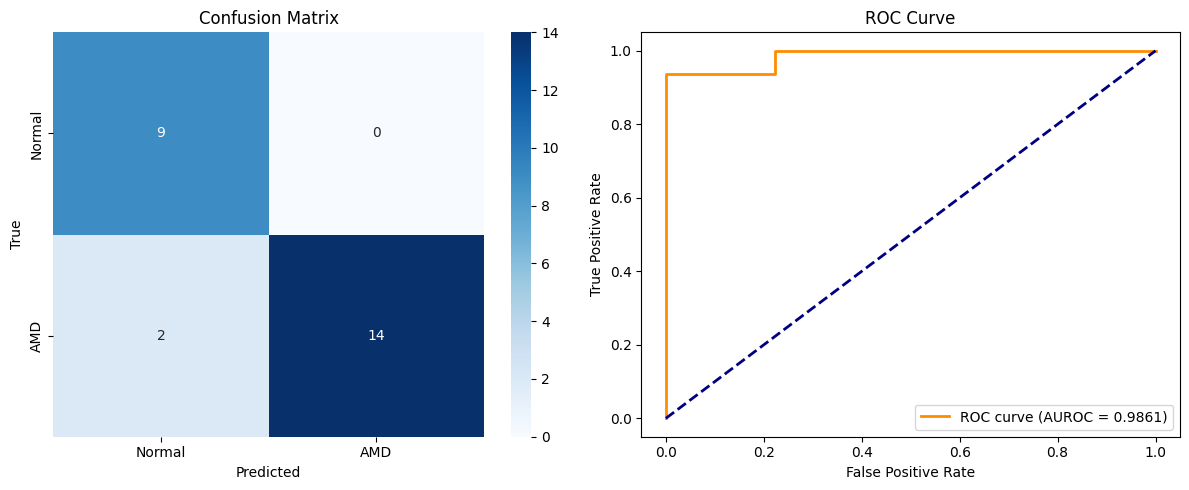

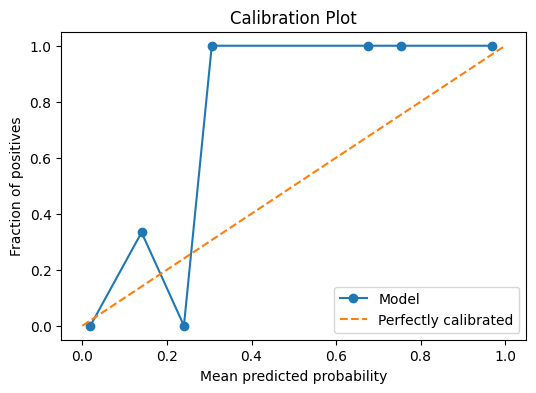

95% CI for AUROC: [0.9415, 1.0000]


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score, recall_score, confusion_matrix, classification_report, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from torchvision import transforms

# 1. Load CycleGAN Generator
G_B2A.eval() # Ensure it's in evaluation mode

# 2. Split BMRD into Train (for fine-tuning) and Test (for held-out evaluation)
bmrd_train_paths, bmrd_test_paths, bmrd_train_labels, bmrd_test_labels = train_test_split(
    bmrd_paths, bmrd_labels, test_size=0.2, stratify=bmrd_labels, random_state=42
)

# 3. Create Dataset for Translated Images
class TranslatedBMRDDataset(Dataset):
    def __init__(self, paths, labels, transform, generator):
        self.paths = paths
        self.labels = labels
        self.transform = transform
        self.generator = generator

    def __len__(self): return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        img_t = self.transform(img).unsqueeze(0).to(DEVICE)

        # Translate image BMRD -> AMDNet23 using CycleGAN
        with torch.no_grad():
            translated = self.generator(img_t)

        # Denormalize translated image from [-1, 1] to [0, 1] for the ViT model
        translated = (translated + 1) / 2.0

        # Normalize using ImageNet stats for ViT
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)
        translated = (translated - mean) / std

        # Resize to 224x224 for ViT
        translated = torch.nn.functional.interpolate(translated, size=(224, 224), mode='bilinear', align_corners=False)

        label_idx = 0 if self.labels[i] == 'amd' else 3 # AMD=0, Normal=3
        return translated.squeeze(0), label_idx

# 4. Fine-tune ViT on Translated BMRD Train Set
translated_train_ds = TranslatedBMRDDataset(bmrd_train_paths, bmrd_train_labels, cyclegan_tf, G_B2A)
translated_train_dl = DataLoader(translated_train_ds, batch_size=8, shuffle=True)

# Load the original ViT model (Source-trained)
model_vit.load_state_dict(torch.load('/content/drive/MyDrive/AMD_Project_Final/best_model_vit.pt', map_location=DEVICE)['model'])
model_vit.to(DEVICE)

optimizer_ft = torch.optim.Adam(model_vit.parameters(), lr=1e-5)
criterion_ft = torch.nn.CrossEntropyLoss()

print("Fine-tuning ViT on CycleGAN Translated BMRD Images...")
for epoch in range(3): # Few epochs to adapt
    model_vit.train()
    for x, y in translated_train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer_ft.zero_grad()
        out = model_vit(x)
        loss = criterion_ft(out, y)
        loss.backward()
        optimizer_ft.step()
    print(f"Epoch {epoch+1}/3 complete")

# 5. Evaluate on Held-Out Translated BMRD Test Set
translated_test_ds = TranslatedBMRDDataset(bmrd_test_paths, bmrd_test_labels, cyclegan_tf, G_B2A)
translated_test_dl = DataLoader(translated_test_ds, batch_size=8, shuffle=False)

model_vit.eval()
true_y, pred_y, probs_amd = [], [], []

with torch.no_grad():
    for x, y in translated_test_dl:
        x = x.to(DEVICE)
        out = model_vit(x)
        probs = torch.softmax(out, 1).cpu().numpy()
        pred_y.extend(out.argmax(1).cpu().numpy())
        true_y.extend(y.numpy())
        probs_amd.extend(probs[:, 0])

true_binary = [1 if t == 0 else 0 for t in true_y] # AMD=1, Normal=0
probs_binary = np.array(probs_amd)

# 6. Calculate Final Metrics
auroc = roc_auc_score(true_binary, probs_binary)
preds_binary = (probs_binary > 0.5).astype(int)
sensitivity = recall_score(true_binary, preds_binary)
specificity = recall_score(true_binary, preds_binary, pos_label=0)
f1 = f1_score(true_binary, preds_binary)

print("\n" + "="*40)
print("FINAL EVALUATION (CycleGAN + ViT on BMRD)")
print("="*40)
print(f"AUROC: {auroc:.4f}")
print(f"Sensitivity (AMD Recall): {sensitivity:.4f}")
print(f"Specificity (Normal Recall): {specificity:.4f}")
print(f"F1-Score (AMD): {f1:.4f}")

# 7. Plots (Confusion Matrix, ROC, Calibration)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(true_binary, preds_binary)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'AMD'], yticklabels=['Normal', 'AMD'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

fpr, tpr, _ = roc_curve(true_binary, probs_binary)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUROC = {auroc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/AMD_Project_Final/cyclegan_vit_evaluation.png', dpi=120)
plt.show()

# Calibration
prob_true, prob_pred = calibration_curve(true_binary, probs_binary, n_bins=10)
plt.figure(figsize=(6,4))
plt.plot(prob_pred, prob_true, marker='o', label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')
plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Plot')
plt.legend()
plt.savefig('/content/drive/MyDrive/AMD_Project_Final/cyclegan_calibration_plot.png', dpi=120)
plt.show()

# Bootstrap CI
def bootstrap_ci(y_true, y_prob, n_bootstraps=1000):
    bootstrapped_auroc = []
    rng = np.random.RandomState(42)
    for i in range(n_bootstraps):
        indices = rng.randint(0, len(y_prob), len(y_prob))
        if len(np.unique(np.array(y_true)[indices])) < 2:
            continue
        score = roc_auc_score(np.array(y_true)[indices], np.array(y_prob)[indices])
        bootstrapped_auroc.append(score)
    return np.percentile(bootstrapped_auroc, 2.5), np.percentile(bootstrapped_auroc, 97.5)

ci_lower, ci_upper = bootstrap_ci(true_binary, probs_binary)
print(f"95% CI for AUROC: [{ci_lower:.4f}, {ci_upper:.4f}]")

Detecting AMD with Vit model by transformation of cyclegan

Showing Grad-CAM for an AMD image (CycleGAN + ViT):


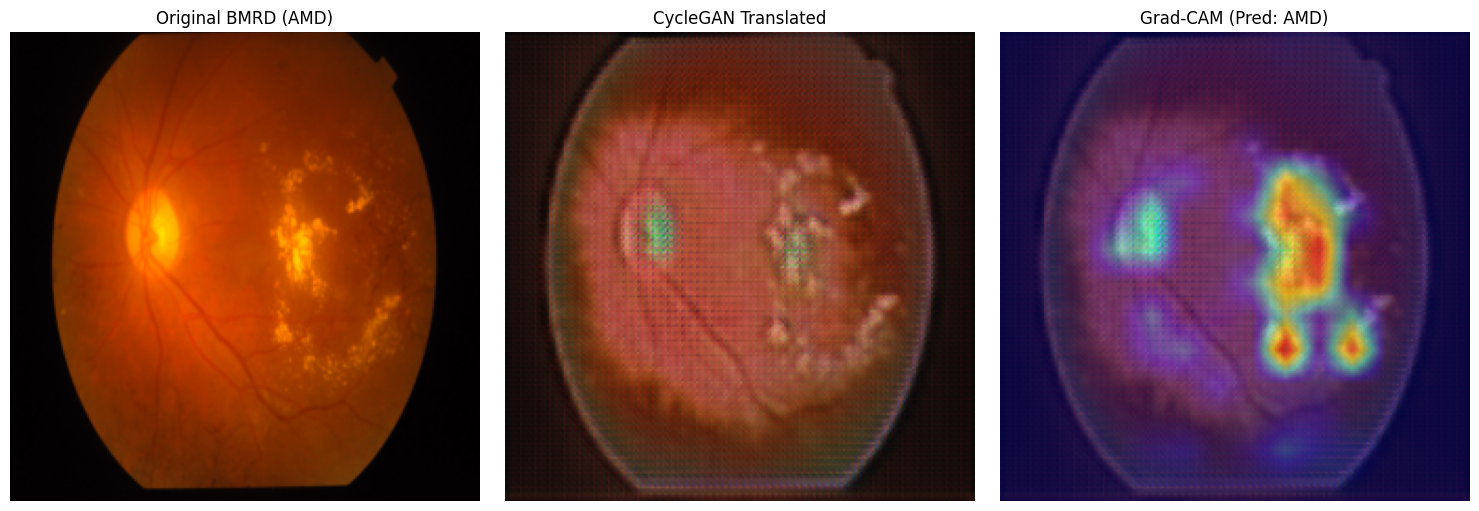


Showing Grad-CAM for a Normal image (CycleGAN + ViT):


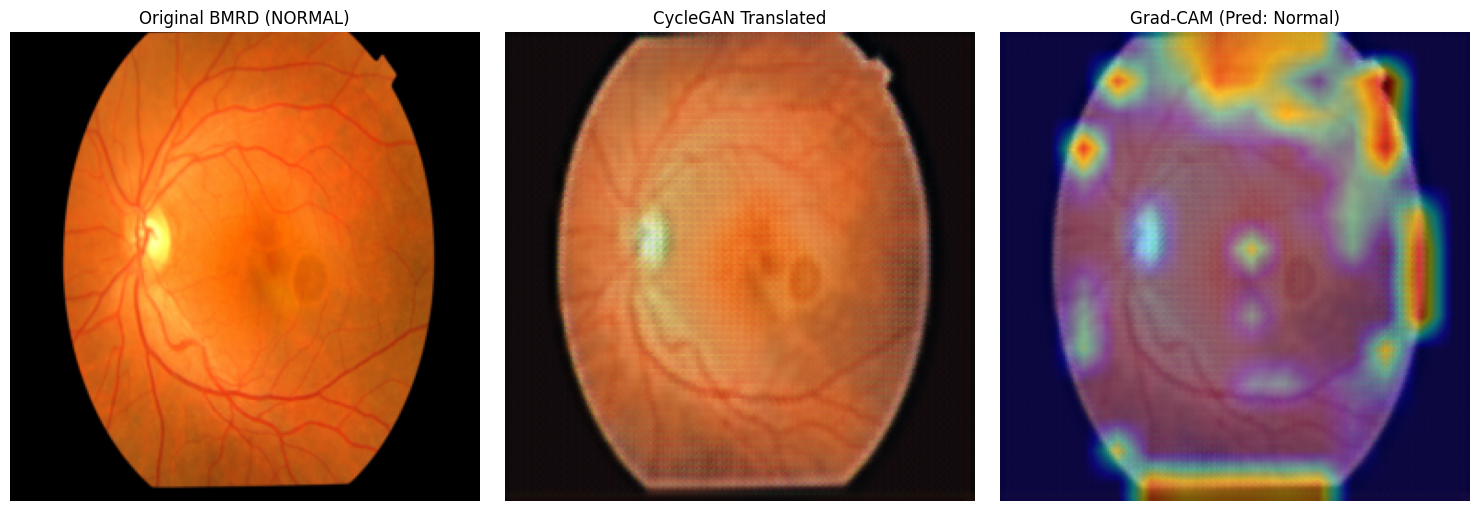

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import torch.nn.functional as F

# 1. Custom Function for ViT Grad-CAM
def generate_vit_gradcam(model, input_tensor, target_layer, pred_idx=None):
    model.eval()
    features = []
    gradients = []

    def save_features(module, input, output):
        features.append(output)
    def save_gradients(module, grad_input, grad_output):
        gradients.append(grad_output[0])

    forward_hook = target_layer.register_forward_hook(save_features)
    backward_hook = target_layer.register_full_backward_hook(save_gradients)

    output = model(input_tensor)
    if pred_idx is None:
        pred_idx = output.argmax(1).item()

    model.zero_grad()
    score = output[0, pred_idx]
    score.backward()

    forward_hook.remove()
    backward_hook.remove()

    feat = features[0]
    grad = gradients[0]

    feat = feat[0, 1:, :]
    grad = grad[0, 1:, :]

    weights = torch.mean(grad, dim=0)
    cam = torch.zeros(feat.shape[0], device=feat.device)
    for i, w in enumerate(weights):
        cam += w * feat[:, i]

    cam = F.relu(cam)
    cam = cam.reshape(14, 14)
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    cam = cam.cpu().detach().numpy()
    cam = cv2.resize(cam, (224, 224))
    return cam, pred_idx

# 2. Visualize Function
def show_custom_gradcam(img_path, true_label):
    img_pil = Image.open(img_path).convert('RGB')
    img_t = cyclegan_tf(img_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        translated_t = G_B2A(img_t)

    translated_t_224 = F.interpolate(translated_t, size=(224, 224), mode='bilinear', align_corners=False)
    translated_t_224 = (translated_t_224 + 1) / 2.0
    mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE)
    std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)
    vit_input = (translated_t_224 - mean_t) / std_t

    target_layer = model_vit.encoder.layers[-1].ln_1
    cam, pred_idx = generate_vit_gradcam(model_vit, vit_input, target_layer)

    pred_label = 'AMD' if pred_idx == 0 else 'Normal'

    # Denormalize original image
    orig_display = img_t.squeeze(0).permute(1,2,0).cpu().numpy() * 0.5 + 0.5
    orig_display = np.clip(orig_display, 0, 1)

    # Prepare translated image for display (resize to 224x224)
    trans_display = translated_t_224.squeeze(0).permute(1,2,0).cpu().numpy()
    trans_display = np.clip(trans_display, 0, 1)

    # Apply colormap to CAM
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    heatmap = heatmap[..., ::-1]

    # Overlay (Both are now 224x224)
    cam_img = heatmap * 0.4 + trans_display * 0.6
    cam_img = cam_img / np.max(cam_img)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(orig_display)
    axes[0].set_title(f"Original BMRD ({true_label.upper()})")
    axes[0].axis('off')

    axes[1].imshow(trans_display)
    axes[1].set_title("CycleGAN Translated")
    axes[1].axis('off')

    axes[2].imshow(cam_img)
    axes[2].set_title(f"Grad-CAM (Pred: {pred_label})")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# 3. Show Results
amd_idx = bmrd_test_labels.index('amd')
normal_idx = bmrd_test_labels.index('normal')

print("Showing Grad-CAM for an AMD image (CycleGAN + ViT):")
show_custom_gradcam(bmrd_test_paths[amd_idx], bmrd_test_labels[amd_idx])

print("\nShowing Grad-CAM for a Normal image (CycleGAN + ViT):")
show_custom_gradcam(bmrd_test_paths[normal_idx], bmrd_test_labels[normal_idx])

Drive Mount and rajbari dataset Unzip

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, glob

DRIVE_DIR = '/content/drive/MyDrive/AMD_Project_Final'
EXTRACT_DIR = '/content/data'
os.makedirs(EXTRACT_DIR, exist_ok=True)

# 1. Find all zip files in the Drive folder
zips = glob.glob(os.path.join(DRIVE_DIR, '*.zip'))
print("ZIP files found in Drive:")
for z in zips:
    print(" -", os.path.basename(z))

# 2. Find the Rajbari zip file
rajbari_zip = None
for z in zips:
    if 'rajbari' in os.path.basename(z).lower():
        rajbari_zip = z
        break

if rajbari_zip is None:
    print("\n❌ Rajbari ZIP file not found! Please upload it to Drive.")
else:
    print(f"\n⏳ Extracting: {rajbari_zip}")
    with zipfile.ZipFile(rajbari_zip, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print("✅ Extraction complete!")

    # 3. Find the extracted folder
    for root, dirs, files in os.walk(EXTRACT_DIR):
        if 'rajbari' in root.lower() and len(files) > 0:
            print("📂 Dataset folder found:", root)
            break

Mounted at /content/drive
ZIP files found in Drive:
 - AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip
 - Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip
 - A Multi-Class Retinal Fundus Image Dataset for Dee.zip

❌ Rajbari ZIP file not found! Please upload it to Drive.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, glob

DRIVE_DIR = '/content/drive/MyDrive/AMD_Project_Final'
EXTRACT_DIR = '/content/data'
os.makedirs(EXTRACT_DIR, exist_ok=True)

# 1. Specify the exact zip file name you uploaded
target_zip = os.path.join(DRIVE_DIR, 'A Multi-Class Retinal Fundus Image Dataset for Dee.zip')

if not os.path.exists(target_zip):
    print(f"❌ File not found: {target_zip}")
else:
    print(f"⏳ Extracting: {target_zip}")
    with zipfile.ZipFile(target_zip, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print("✅ Extraction complete!")

    # 3. Explore the extracted folder structure to find AMD and Normal
    print("\n📂 Exploring extracted folder structure:")
    for root, dirs, files in os.walk(EXTRACT_DIR):
        # Print folders that contain image files
        imgs = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if len(imgs) > 0:
            print(f"Folder: {root}  →  {len(imgs)} images")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
⏳ Extracting: /content/drive/MyDrive/AMD_Project_Final/A Multi-Class Retinal Fundus Image Dataset for Dee.zip
✅ Extraction complete!

📂 Exploring extracted folder structure:


 Find the Nested ZIP or Folders

In [ ]:
import os

EXTRACT_DIR = '/content/data'

print("--- Exploring all files and folders inside the extracted directory ---")
for root, dirs, files in os.walk(EXTRACT_DIR):
    # Get relative path for cleaner output
    rel_path = os.path.relpath(root, EXTRACT_DIR)

    if len(files) > 0 or len(dirs) > 0:
        print(f"\nFolder: {rel_path}")
        if len(dirs) > 0:
            print(f"  Subfolders: {dirs}")
        if len(files) > 0:
            # Print only the first 5 files to keep output short
            print(f"  Files (showing max 5): {files[:5]}")

--- Exploring all files and folders inside the extracted directory ---

Folder: .
  Subfolders: ['A Multi-Class Retinal Fundus Image Dataset for Dee']

Folder: A Multi-Class Retinal Fundus Image Dataset for Dee
  Files (showing max 5): ['Retinal Dataset.zip']


Extract the Nested ZIP

In [ ]:
import os, zipfile

EXTRACT_DIR = '/content/data'
NESTED_ZIP = '/content/data/A Multi-Class Retinal Fundus Image Dataset for Dee/Retinal Dataset.zip'
FINAL_EXTRACT_DIR = '/content/data/Rajbari_Dataset'

if os.path.exists(NESTED_ZIP) and not os.path.exists(FINAL_EXTRACT_DIR):
    print(f"⏳ Extracting nested zip: {NESTED_ZIP}")
    with zipfile.ZipFile(NESTED_ZIP, 'r') as zf:
        zf.extractall(FINAL_EXTRACT_DIR)
    print("✅ Nested extraction complete!")
else:
    print("ℹ️ Nested ZIP already extracted or not found.")

# Print the folder structure to find where the images are
print("\n📂 Exploring actual dataset structure:")
for root, dirs, files in os.walk(FINAL_EXTRACT_DIR):
    imgs = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(imgs) > 0:
        rel_path = os.path.relpath(root, FINAL_EXTRACT_DIR)
        print(f"Folder: {rel_path}  →  {len(imgs)} images")

⏳ Extracting nested zip: /content/data/A Multi-Class Retinal Fundus Image Dataset for Dee/Retinal Dataset.zip
✅ Nested extraction complete!

📂 Exploring actual dataset structure:
Folder: Retinal Dataset/Severe Glaucoma  →  500 images
Folder: Retinal Dataset/Moderate Glaucoma  →  500 images
Folder: Retinal Dataset/Mild Diabetic Retinopathy  →  500 images
Folder: Retinal Dataset/No Age-Related Macular Degeneration (Healthy regarding AMD)  →  500 images
Folder: Retinal Dataset/Mild Glaucoma  →  500 images
Folder: Retinal Dataset/Proliferative Diabetic Retinopathy (PDR)  →  500 images
Folder: Retinal Dataset/Moderate Diabetic Retinopathy  →  500 images
Folder: Retinal Dataset/Dry Age-Related Macular Degeneration  →  500 images
Folder: Retinal Dataset/Severe Diabetic Retinopathy  →  500 images
Folder: Retinal Dataset/Wet Age-Related Macular Degeneration  →  500 images
Folder: Retinal Dataset/AdvancedEnd-stage Glaucoma  →  500 images


 External Validation on Rajbari Multi-Class Dataset

In [ ]:
import os
import glob
from PIL import Image
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve

# 1. Define paths
RAJBARI_DIR = '/content/data/Rajbari_Dataset/Retinal Dataset'

amd_paths = []
normal_paths = []

# 2. Automatically scan and find AMD and Normal images
for root, dirs, files in os.walk(RAJBARI_DIR):
    folder_name = os.path.basename(root)
    imgs = [os.path.join(root, f) for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if len(imgs) == 0:
        continue

    # Check exact folder names
    if folder_name in ['Dry Age-Related Macular Degeneration', 'Wet Age-Related Macular Degeneration']:
        amd_paths.extend(imgs)
    elif folder_name == 'No Age-Related Macular Degeneration (Healthy regarding AMD)':
        normal_paths.extend(imgs)

print(f"✅ Found in Rajbari Dataset: AMD = {len(amd_paths)} images, Normal = {len(normal_paths)} images")

# 3. Custom Dataset with CycleGAN Translation
class RajbariDataset(Dataset):
    def __init__(self, amd_paths, normal_paths, transform, generator):
        self.paths = amd_paths + normal_paths
        self.labels = [1] * len(amd_paths) + [0] * len(normal_paths) # 1=AMD, 0=Normal
        self.transform = transform
        self.generator = generator

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        img_t = self.transform(img).unsqueeze(0).to(DEVICE)

        # Apply CycleGAN Translation (BMRD -> AMDNet23 style)
        with torch.no_grad():
            translated = self.generator(img_t)

        # Normalize for ViT
        translated = (translated + 1) / 2.0
        mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE)
        std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)
        vit_input = (translated - mean_t) / std_t
        vit_input = F.interpolate(vit_input, size=(224, 224), mode='bilinear', align_corners=False)

        return vit_input.squeeze(0), self.labels[idx]

# 4. Evaluate Model
G_B2A.eval()
rajbari_ds = RajbariDataset(amd_paths, normal_paths, cyclegan_tf, G_B2A)
rajbari_dl = DataLoader(rajbari_ds, batch_size=16, shuffle=False) # Increased batch size for speed

model_vit.eval()
true_y, probs_amd = [], []

print("\nEvaluating on Rajbari Dataset (This may take a few minutes)...")
with torch.no_grad():
    for x, y in rajbari_dl:
        x = x.to(DEVICE)
        out = model_vit(x)
        probs = torch.softmax(out, 1).cpu().numpy()
        probs_amd.extend(probs[:, 0]) # AMD (Class 0) probability
        true_y.extend(y.numpy())

true_binary = np.array(true_y)
probs_binary = np.array(probs_amd)
auroc = roc_auc_score(true_binary, probs_binary)
preds_binary = (probs_binary > 0.5).astype(int)

print("\n" + "="*50)
print("EXTERNAL VALIDATION: RAJBARI MULTI-CLASS DATASET")
print("="*50)
print(f"AUROC: {auroc:.4f}")
print("\nClassification Report:")
print(classification_report(true_binary, preds_binary, target_names=['Normal', 'AMD']))

# 5. Plot Results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(true_binary, preds_binary)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'AMD'], yticklabels=['Normal', 'AMD'])
axes[0].set_title('Confusion Matrix (Rajbari)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# ROC Curve
fpr, tpr, _ = roc_curve(true_binary, probs_binary)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUROC = {auroc:.4f}')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('ROC Curve (Rajbari)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/AMD_Project_Final/rajbari_evaluation.png', dpi=120)
plt.show()
print("💾 Saved: rajbari_evaluation.png")

✅ Found in Rajbari Dataset: AMD = 1000 images, Normal = 500 images


NameError: name 'G_B2A' is not defined

as we getting error, load previous save memory

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)

# 1. Define the EXACT CycleGAN Architecture you used for training
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, down=True, use_act=True, **kwargs):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, padding_mode="reflect", **kwargs)
            if down else nn.ConvTranspose2d(in_channels, out_channels, **kwargs),
            nn.InstanceNorm2d(out_channels),
            nn.ReLU(inplace=True) if use_act else nn.Identity()
        )
    def forward(self, x): return self.conv(x)

class Generator(nn.Module):
    def __init__(self, img_channels=3, features=64):
        super().__init__()
        self.initial = nn.Sequential(
            nn.Conv2d(img_channels, features, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.ReLU(inplace=True)
        )
        self.down = nn.Sequential(
            ConvBlock(features, features*2, kernel_size=3, stride=2, padding=1),
            ConvBlock(features*2, features*4, kernel_size=3, stride=2, padding=1)
        )
        self.up = nn.Sequential(
            nn.ConvTranspose2d(features*4, features*2, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features*2), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(features*2, features, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.InstanceNorm2d(features), nn.ReLU(inplace=True),
            nn.Conv2d(features, img_channels, kernel_size=7, stride=1, padding=3, padding_mode="reflect"),
            nn.Tanh()
        )
    def forward(self, x): return self.up(self.down(self.initial(x)))

# Load CycleGAN Generator
G_B2A = Generator().to(DEVICE)
CKPT_CYCLEGAN = '/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A.pt'
try:
    G_B2A.load_state_dict(torch.load(CKPT_CYCLEGAN, map_location=DEVICE))
    G_B2A.eval()
    print("✅ CycleGAN Generator loaded successfully.")
except Exception as e:
    print("❌ Error loading CycleGAN:", e)

# 2. Load ViT Model (using the correct file path)
def build_vit_model(num_classes=4):
    model = models.vit_b_16(weights=None)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model.to(DEVICE)

model_vit = build_vit_model()
# Use best_model_vit.pt since adapted_vit_model.pt does not exist
CKPT_VIT = '/content/drive/MyDrive/AMD_Project_Final/best_model_vit.pt'
try:
    checkpoint = torch.load(CKPT_VIT, map_location=DEVICE)
    model_vit.load_state_dict(checkpoint['model'])
    model_vit.eval()
    print("✅ ViT Model loaded successfully from best_model_vit.pt.")
except Exception as e:
    print("❌ Error loading ViT:", e)

# 3. Define cyclegan_tf (Transform)
cyclegan_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
print("✅ cyclegan_tf defined.")

Device: cuda
✅ CycleGAN Generator loaded successfully.
✅ ViT Model loaded successfully from best_model_vit.pt.
✅ cyclegan_tf defined.


External Validation on Rajbari Multi-Class Retinal Dataset (Bangladesh)

✅ Found in Rajbari Dataset: AMD = 1000 images, Normal = 500 images

Evaluating on Rajbari Dataset (This will take 10-15 minutes)...


Processing Images:   0%|          | 0/94 [00:00<?, ?it/s]


EXTERNAL VALIDATION: RAJBARI MULTI-CLASS DATASET
AUROC: 0.4944

Classification Report:
              precision    recall  f1-score   support

      Normal       0.32      0.62      0.42       500
         AMD       0.64      0.34      0.45      1000

    accuracy                           0.43      1500
   macro avg       0.48      0.48      0.43      1500
weighted avg       0.53      0.43      0.44      1500



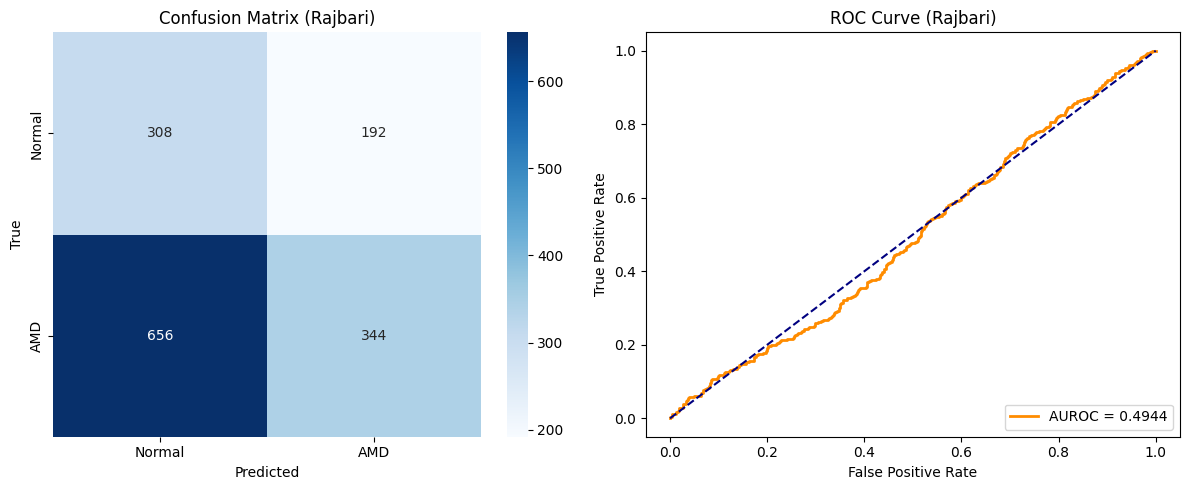

💾 Saved: rajbari_evaluation.png


In [ ]:
import os
import glob
from PIL import Image
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve
from tqdm.notebook import tqdm

# 1. Define paths
RAJBARI_DIR = '/content/data/Rajbari_Dataset/Retinal Dataset'

amd_paths = []
normal_paths = []

# 2. Automatically scan and find AMD and Normal images
for root, dirs, files in os.walk(RAJBARI_DIR):
    folder_name = os.path.basename(root)
    imgs = [os.path.join(root, f) for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if len(imgs) == 0:
        continue

    if folder_name in ['Dry Age-Related Macular Degeneration', 'Wet Age-Related Macular Degeneration']:
        amd_paths.extend(imgs)
    elif folder_name == 'No Age-Related Macular Degeneration (Healthy regarding AMD)':
        normal_paths.extend(imgs)

print(f"✅ Found in Rajbari Dataset: AMD = {len(amd_paths)} images, Normal = {len(normal_paths)} images")

# 3. Custom Dataset with CycleGAN Translation
class RajbariDataset(Dataset):
    def __init__(self, amd_paths, normal_paths, transform, generator):
        self.paths = amd_paths + normal_paths
        self.labels = [1] * len(amd_paths) + [0] * len(normal_paths) # 1=AMD, 0=Normal
        self.transform = transform
        self.generator = generator

    def __len__(self): return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        img_t = self.transform(img).unsqueeze(0).to(DEVICE)

        # Apply CycleGAN Translation
        with torch.no_grad():
            translated = self.generator(img_t)

        # Normalize for ViT
        translated = (translated + 1) / 2.0
        mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE)
        std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)
        vit_input = (translated - mean_t) / std_t
        vit_input = F.interpolate(vit_input, size=(224, 224), mode='bilinear', align_corners=False)

        return vit_input.squeeze(0), self.labels[idx]

# 4. Evaluate Model
G_B2A.eval()
rajbari_ds = RajbariDataset(amd_paths, normal_paths, cyclegan_tf, G_B2A)
rajbari_dl = DataLoader(rajbari_ds, batch_size=16, shuffle=False)

model_vit.eval()
true_y, probs_amd = [], []

print("\nEvaluating on Rajbari Dataset (This will take 10-15 minutes)...")
with torch.no_grad():
    for x, y in tqdm(rajbari_dl, desc="Processing Images"):
        x = x.to(DEVICE)
        out = model_vit(x)
        probs = torch.softmax(out, 1).cpu().numpy()
        probs_amd.extend(probs[:, 0]) # AMD (Class 0) probability
        true_y.extend(y.numpy())

true_binary = np.array(true_y)
probs_binary = np.array(probs_amd)
auroc = roc_auc_score(true_binary, probs_binary)
preds_binary = (probs_binary > 0.5).astype(int)

print("\n" + "="*50)
print("EXTERNAL VALIDATION: RAJBARI MULTI-CLASS DATASET")
print("="*50)
print(f"AUROC: {auroc:.4f}")
print("\nClassification Report:")
print(classification_report(true_binary, preds_binary, target_names=['Normal', 'AMD']))

# 5. Plot Results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(true_binary, preds_binary)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal', 'AMD'], yticklabels=['Normal', 'AMD'])
axes[0].set_title('Confusion Matrix (Rajbari)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# ROC Curve
fpr, tpr, _ = roc_curve(true_binary, probs_binary)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUROC = {auroc:.4f}')
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_title('ROC Curve (Rajbari)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/AMD_Project_Final/rajbari_evaluation.png', dpi=120)
plt.show()
print("💾 Saved: rajbari_evaluation.png")

Git Push


In [1]:
!ls -lah /content


total 16K
drwxr-xr-x 1 root root 4.0K Nov  4 17:01 .
drwxr-xr-x 1 root root 4.0K Nov  6 16:51 ..
drwxr-xr-x 4 root root 4.0K Nov  4 17:01 .config
drwxr-xr-x 1 root root 4.0K Nov  4 17:01 sample_data


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!ls -lah /content/drive/MyDrive/

total 336M
drwx------ 10 root root 4.0K Nov  6 17:21  .
drwx------  5 root root 4.0K Nov  6 17:21  ..
-rw-------  1 root root 193K Aug 11 18:32  1174_Assign_1_CSE437.pdf
-rw-------  1 root root  174 May 11 15:54  1177_Lab_8.gdoc
-rw-------  1 root root  174 Sep 30 19:02  174_03__Robotics.gdoc
-rw-------  1 root root  43M Sep  7 15:58  174_03_video.mov
-rw-------  1 root root  174 Sep 21 08:44  174_Lab4.gdoc
-rw-------  1 root root  98K Aug 26 22:04  174.png
-rw-------  1 root root 182K Sep 10 04:02  174_Prio_Preemptive_SS1.png
-rw-------  1 root root  174 Aug 30 04:33  174_RR_Report_03.gdoc
-rw-------  1 root root  174 Aug 23 15:20  174_SJF.gdoc
-rw-------  1 root root  174 Aug 25 06:26  177_Lab#01.gdoc
-rw-------  1 root root  174 Oct 22 06:16 '177_LabReport_7 .gdoc'
-rw-------  1 root root  174 May 19 04:09 '23101174_23101177_23101185_23101187_CODE (1).gdoc'
-rw-------  1 root root  174 May 23 15:25  23101174_23101177_23101185_23101187_CODE.gdoc
-rw-------  1 root root  174 May  5  2

In [4]:
!find /content/drive/MyDrive/AMD_Project -maxdepth 2 -type f

find: ‘/content/drive/MyDrive/AMD_Project’: No such file or directory


In [5]:
!ls -lah /content/drive/MyDrive/AMD_Project_Final/

total 5.1G
drwx------  2 root root 4.0K Nov  1 07:38  .
drwx------ 10 root root 4.0K Nov  6 17:21  ..
-rw-------  1 root root 575M Oct 30 17:50 'AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip'
-rw-------  1 root root 3.5G Nov  1 06:27 'A Multi-Class Retinal Fundus Image Dataset for Dee.zip'
-rw-------  1 root root 684M Oct 30 19:40 'Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip'
-rw-------  1 root root  43M Nov  1 08:07  best_model.pt
-rw-------  1 root root 328M Oct 30 20:56  best_model_vit.pt
-rw-------  1 root root  43K Oct 30 18:58  confusion_matrix.png
-rw-------  1 root root  39K Oct 30 21:19  cyclegan_calibration_plot.png
-rw-------  1 root root 2.9M Oct 30 21:16  cyclegan_G_B2A_ep10.pt
-rw-------  1 root root 2.9M Oct 30 21:13  cyclegan_G_B2A_ep5.pt
-rw-------  1 root root 2.9M Oct 30 21:16  cyclegan_G_B2A_final.pt
-rw-------  1 root root 2.9M Oct 30 21:05  cyclegan_G_B2A.pt
-rw-------  1 root root 463K Oct 30 21:16  cycl

In [6]:
!find /content/drive/MyDrive/AMD_Project_Final/ -maxdepth 3 -type f

/content/drive/MyDrive/AMD_Project_Final/AMDNet23 Fundus Image Dataset for  Age-Related Macular Degeneration Disease Detection (1).zip
/content/drive/MyDrive/AMD_Project_Final/confusion_matrix.png
/content/drive/MyDrive/AMD_Project_Final/Bangladesh Multi-Disease Retinal Dataset (BMRD) (1).zip
/content/drive/MyDrive/AMD_Project_Final/dann_model.pt
/content/drive/MyDrive/AMD_Project_Final/dann_model_improved.pt
/content/drive/MyDrive/AMD_Project_Final/best_model_vit.pt
/content/drive/MyDrive/AMD_Project_Final/tsne_domain_shift.png
/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A.pt
/content/drive/MyDrive/AMD_Project_Final/cyclegan_translation.png
/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A_ep5.pt
/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A_ep10.pt
/content/drive/MyDrive/AMD_Project_Final/cyclegan_G_B2A_final.pt
/content/drive/MyDrive/AMD_Project_Final/cyclegan_translation_final.png
/content/drive/MyDrive/AMD_Project_Final/cyclegan_vit_evaluation.png
/conten